# 3r_migration_kumamoto: in- and out-migration by age around the 2016 Kumamoto Earthquake, by cohort

The 45 municipalities listed under 熊本 in `dt/analysis_original_data.xlsx` (sheet `1_市町村一覧`). The notebook has three parts:

1. **Single-year ages with `ungroup`** (figures 1–2). Population and migrants are published in 5-year bands. `ungroup::pclm()` (penalized composite link model; Rizzi et al. 2015) splits each municipality-year into single years of age 0–104, and keeps every band's total. Figures 1–2 show what that looks like for a large, a medium and a small municipality.
2. **5-year profiles before, during and after the earthquake** (figure 3). These are the published bands, with no ungrouping: in-, out- and net-migration rates per 1,000 residents of the same age band.
3. **Cohort movement rates** (figures 4–7).
   - **Cohorts:** the 5-year age groups on the last count before the earthquake (2016-01-01), followed year by year as they age.
   - **Rate:** in each year *t*, the cohort's movers ÷ the cohort's own population on 1 January *t*, per 1,000. Each year is computed on its own.
   - **Back-cast:** 2014–2015 trace the same cohorts back for a pre-quake reference.
4. **Change from the pre-quake baseline** (figures 8–12). Net migration in each year minus the 2014–15 reference (the mean of the 2014 and 2015 values): each band's contribution to the all-ages rate, stacked by group (figure 8); each band's own rate, by group (figure 10 as lines, figure 11 as a heatmap) and per municipality for every band (figure 9). Figure 12 is figure 8 without the baseline subtracted: each band's contribution to the all-ages net migration rate itself.
5. **全壊率 vs net migration in 2016** (figures 13–14): one point per municipality, with Spearman ρ; figure 14 shows only the change relative to 2014–15.

**Data**
- **Migrants:** `dt/idou_age_sex_5yr_long.qs2`, built by `src/build_idou_age.R` from 住民基本台帳人口移動報告 (総務省統計局; e-Stat 00200523).
  - 転入 = in-migrants from other municipalities; 転出 = out-migrants to other municipalities. Moves within a municipality, births and deaths are not included.
  - **Japanese movers (日本人移動者) only.** The 2014–2017 tables publish no other basis.
  - Municipal 5-year age × sex detail exists only from 2014 (see `doc/data.md`).
  - Years used: 2014–2025, calendar years.
- **Population:** `dt/jumin_age_sex_5yr_long.qs2` (住民基本台帳), Japanese residents (`basis == "japanese"`) to match the movers. Counts on 1 January of each year, both sexes.
  - The top band is 80+ in 2014 and 100+ from 2015.

**Approximations** (see `doc/caution.md`)
- **Lexis.** Movers in year *t* reported at age *x* are split evenly between the cohorts aged *x* and *x*−1 on 1 January *t*. In other words, the cohort aged *x* on 1 January gets ½·(M<sub>x</sub> + M<sub>x+1</sub>). This assumes the reported age is age at the move and that moves are spread evenly over the year.
- **ungroup uncertainty.** Fits for small municipalities and for migrant counts are smooth guesses. The band totals are exact, but the shape within a band is not.

Figures are also written to `res/` as `3r_<NN>_<item>.png` via `show_save()`. Tables are shown here only. The pclm fits are cached in `output/3r_pclm_cache.qs2`; delete it to refit (a few minutes).

In [1]:
suppressWarnings(suppressPackageStartupMessages({
  library(dplyr)
  library(tidyr)
  library(ggplot2)
  library(qs2)
  library(ungroup)
}))
options(repr.plot.width = 16, repr.plot.height = 9, repr.plot.res = 110,
        jupyter.plot_mimetypes = "image/png")

# The notebook lives in src/; resolve the repo root so paths work from either.
root <- if (dir.exists("dt")) "." else ".."
res_dir <- file.path(root, "res")
dir.create(res_dir, showWarnings = FALSE)
surface <- "#fcfcfb"
ink <- "#2b2b29"; ink2 <- "#5c5c58"; ink3 <- "#8a8a85"; grid_col <- "#e6e5e1"
jp_font <- "Noto Sans CJK JP"   # conda font-ttf-noto-cjk (pinned in the Dockerfile)

nb_prefix <- "3r_"
show_save <- function(p, name, width = 16, height = 9) {
  ggsave(file.path(res_dir, paste0(nb_prefix, name, ".png")), p,
         width = width, height = height, dpi = 150, bg = surface)
  print(p)
  invisible(p)
}

years <- 2014:2025      # calendar years of migration; population on 1 January
base_year <- 2016       # 2016-01-01: last count before the 2016-04-14/16 earthquake
event_x <- 2016         # the quake falls inside calendar year 2016
top_age <- 105          # single years 0..104; open bands are spread up to here

base_theme <- function() list(
  theme_minimal(base_size = 10, base_family = jp_font),
  theme(
    plot.background = element_rect(fill = surface, colour = NA),
    panel.grid.minor = element_blank(),
    panel.grid.major.x = element_blank(),
    panel.grid.major.y = element_line(colour = grid_col, linewidth = 0.3),
    panel.spacing = unit(0.5, "cm"),
    strip.text = element_text(face = "bold", hjust = 0, colour = ink, size = 9.5),
    plot.title = element_text(face = "bold", size = 14),
    plot.subtitle = element_text(colour = ink2, size = 10),
    plot.caption = element_text(colour = ink3, size = 8, hjust = 0),
    plot.title.position = "plot",
    plot.caption.position = "plot",
    axis.text = element_text(colour = ink2, size = 8),
    axis.title = element_text(colour = ink2, size = 10),
    legend.position = "top",
    legend.justification = "left",
    legend.text = element_text(size = 10)
  )
)
src_note <- paste0("Migrants: 住民基本台帳人口移動報告 (Statistics Bureau, e-Stat), Japanese movers between municipalities. ",
                   "Population: Basic Resident Register, Japanese residents, 1 January.")

In [2]:
# Study municipalities and the high-damage group (全壊率 >= 1)
study <- readxl::read_excel(file.path(root, "dt/analysis_original_data.xlsx"),
                            sheet = "1_市町村一覧", col_types = "text") |>
  filter(災害 == "熊本") |>
  transmute(code = 市町村コード, muni = 市町村, short = sub("^.*郡", "", 市町村),
            zenkai_rate = as.numeric(`全壊率(全壊棟数/人口×100)`)) |>
  mutate(group = case_when(zenkai_rate >= 1 ~ "High damage (全壊率 ≥ 1)",
                           code == "43100" ~ "熊本市",
                           TRUE ~ "Other listed municipalities"))
group_levels <- c("High damage (全壊率 ≥ 1)", "熊本市", "Other listed municipalities")
group_cols <- setNames(c("#eb6834", "#2a78d6", "#1baf7a"), group_levels)

pop5 <- qs_read(file.path(root, "dt/jumin_age_sex_5yr_long.qs2")) |>
  filter(code %in% study$code, basis == "japanese", sex == "計", year %in% years) |>
  mutate(age_band = as.character(age_band)) |>
  select(code, year, age_band, n = pop)

mig5 <- qs_read(file.path(root, "dt/idou_age_sex_5yr_long.qs2")) |>
  filter(code %in% study$code, level == "municipality", mover == "japanese", sex == "計",
         year %in% years, age_band != "origin_unknown") |>
  mutate(age_band = as.character(age_band)) |>
  select(code, year, direction, age_band, n)

# Coverage: every municipality has population and both directions in every year
bind_rows(pop5 |> mutate(series = "population"),
          mig5 |> mutate(series = direction)) |>
  filter(age_band == "total") |>
  group_by(series) |>
  summarise(municipalities = n_distinct(code), years = paste(range(year), collapse = "–"),
            code_years = n(), missing = sum(is.na(n)), total = sum(n), .groups = "drop") |>
  as.data.frame()
study |> count(group) |> as.data.frame()

series,municipalities,years,code_years,missing,total
<chr>,<int>,<chr>,<int>,<int>,<dbl>
in,45,2014–2025,540,0,834104
out,45,2014–2025,540,0,869676
population,45,2014–2025,540,0,21084287


group,n
<chr>,<int>
High damage (全壊率 ≥ 1),5
Other listed municipalities,39
熊本市,1


## 1. From 5-year bands to single years with `ungroup`

`pclm(x, y, nlast)` takes the lower bound of each band (`x`), the counts (`y`) and the width of the open last band (`nlast`). It returns a smooth single-year distribution whose sums over each band equal the input counts. The smoothing parameter λ is chosen by BIC for each fit.

- **Open bands:** population's open top band is spread over 100–104 (80–104 in 2014) and migrants' 90+ over 90–104.
- **Below:** the 2016-01-01 population and the 2016 movers for three municipalities of very different size. Bars are the published bands drawn as counts per single year (band count ÷ band width); the line is the pclm fit with its 95% interval.
- **Smoothing (λ in the table):** λ grows as counts shrink. For 五木村 (~1,200 residents, ~40 movers) it reaches pclm's upper search bound (≈1e5), so the fit is close to the smoothest curve that still matches the band totals. Its within-band shape carries almost no information.

In [3]:
# Band label -> lower bound ("0_4" -> 0, "80+" -> 80). Drops the total and, when
# the finer 80-84 ... 100+ bands are present, the harmonised 80+.
band_table <- function(bands, counts) {
  keep <- bands != "total"
  if (any(bands == "80_84")) keep <- keep & bands != "80+"
  tibble(band = bands[keep], n = counts[keep]) |>
    mutate(lower = as.integer(sub("[_+].*", "", band))) |>
    arrange(lower) |>
    mutate(upper = lead(lower, default = top_age))   # bands are contiguous; open band ends at top_age
}

# Single-year ages 0..top_age-1 from one set of bands
ungroup_bands <- function(bands, counts) {
  b <- band_table(bands, counts)
  if (sum(b$n) == 0) {
    return(tibble(age = 0:(top_age - 1), fit = 0, lo = 0, hi = 0, lambda = NA_real_))
  }
  # pclm advises against zero counts (sparse migrant bands in small villages);
  # replace them with a negligible 1e-4 as the package's message suggests.
  m <- pclm(x = b$lower, y = pmax(b$n, 1e-4), nlast = top_age - max(b$lower), verbose = FALSE)
  tibble(age = 0:(top_age - 1), fit = unname(fitted(m)),
         lo = unname(m$ci$lower), hi = unname(m$ci$upper),
         lambda = unname(m$smoothPar["lambda"]))
}

In [4]:
showcase <- study |> filter(short %in% c("熊本市", "益城町", "五木村")) |>
  mutate(short = factor(short, levels = c("熊本市", "益城町", "五木村")))

demo <- function(src, yr) {
  src |>
    filter(code %in% showcase$code, year == yr) |>
    group_by(across(any_of(c("code", "direction")))) |>
    group_modify(function(g, key) {
      bars <- band_table(g$age_band, g$n)
      fit <- ungroup_bands(g$age_band, g$n)
      bind_rows(bars |> mutate(kind = "bars"), fit |> mutate(kind = "fit"))
    }) |>
    ungroup() |>
    left_join(showcase |> select(code, short), by = "code")
}
demo_pop <- demo(pop5, base_year)
demo_mig <- demo(mig5, base_year)

# Check: single-year fits add back to the published band totals
bind_rows(demo_pop |> mutate(direction = "population"), demo_mig) |>
  group_by(short, direction) |>
  summarise(band_total = sum(n[kind == "bars"]), fit_total = round(sum(fit[kind == "fit"]), 1),
            lambda = round(first(na.omit(lambda)), 1), .groups = "drop") |>
  as.data.frame()

short,direction,band_total,fit_total,lambda
<fct>,<chr>,<dbl>,<dbl>,<dbl>
熊本市,in,41711,41711,1149.6
熊本市,out,43251,43251,1674.7
熊本市,population,730589,730589,0.3
益城町,in,1165,1165,10183.0
益城町,out,2484,2484,12451.7
益城町,population,34503,34503,8944.5
五木村,in,41,41,99999.6
五木村,out,46,46,99999.6
五木村,population,1186,1186,99999.6


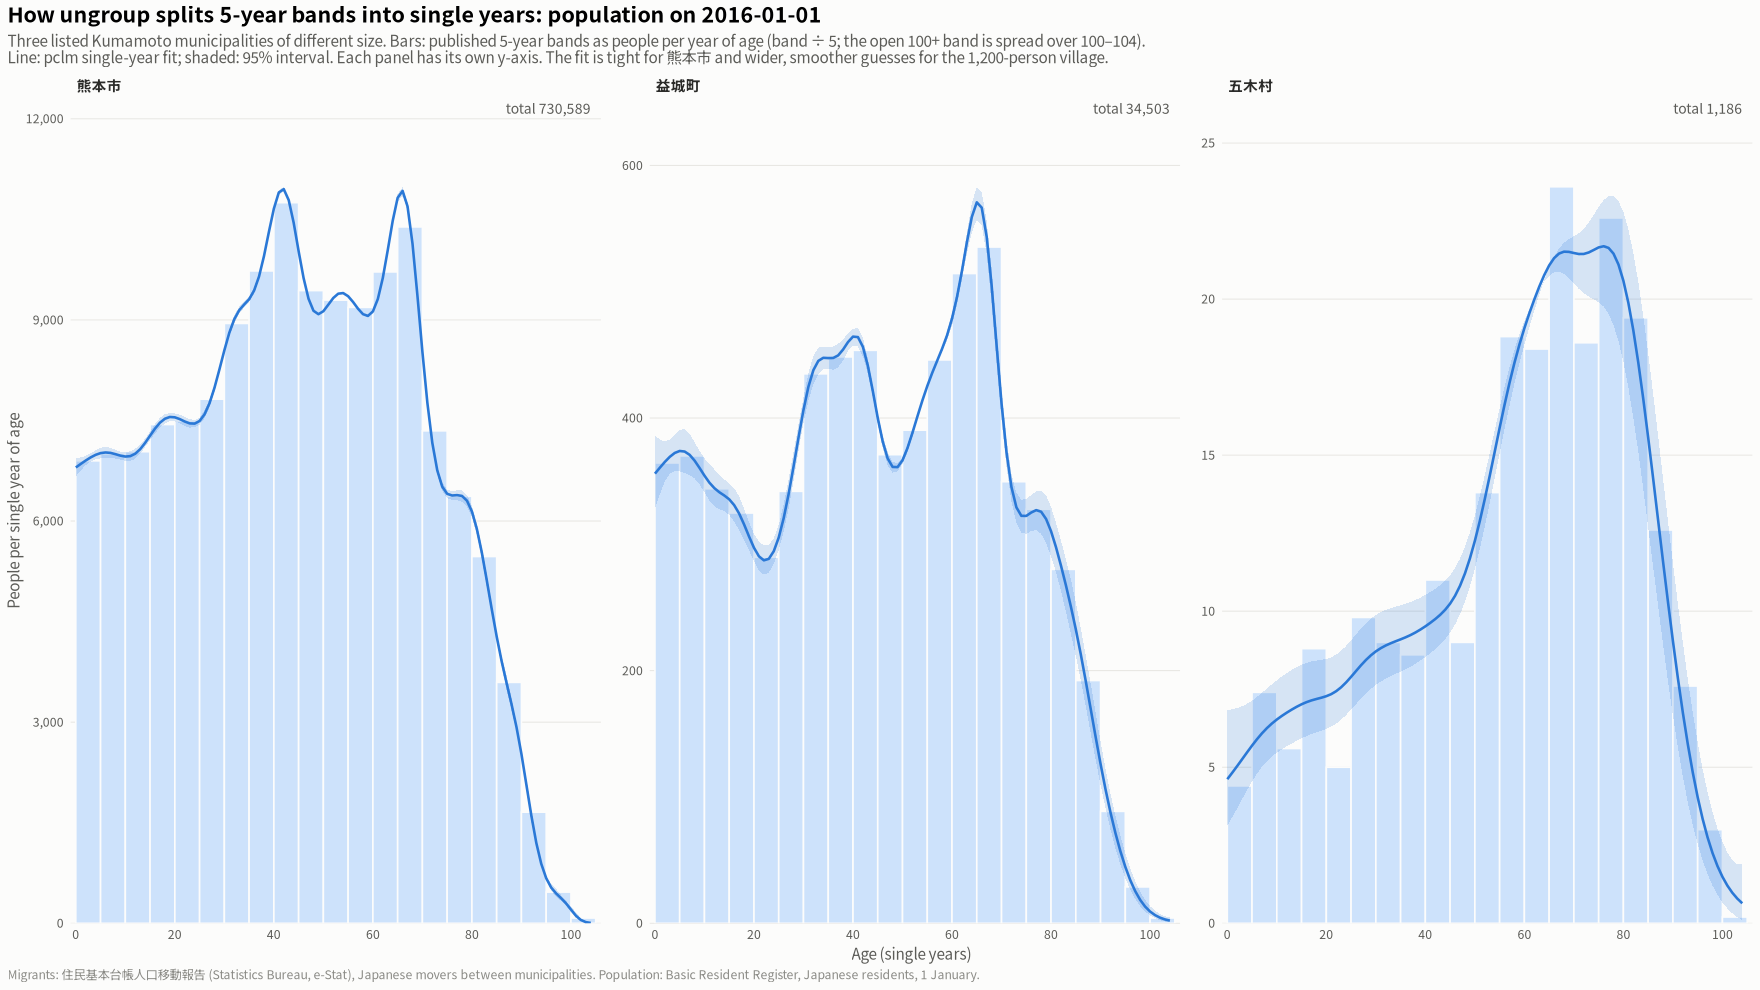

In [5]:
plot_demo <- function(dd, facet, title, subtitle, ylab) {
  bars <- dd |> filter(kind == "bars") |> mutate(per_year = n / (upper - lower))
  fit <- dd |> filter(kind == "fit")
  lab <- bars |> group_by(across(all_of(facet))) |> summarise(total = sum(n), .groups = "drop")
  ggplot() +
    geom_rect(data = bars, aes(xmin = lower, xmax = upper, ymin = 0, ymax = per_year),
              fill = "#cde2fb", colour = surface, linewidth = 0.5) +
    geom_ribbon(data = fit, aes(age, ymin = lo, ymax = hi), fill = "#2a78d6", alpha = 0.18) +
    geom_line(data = fit, aes(age, fit), colour = "#2a78d6", linewidth = 0.8) +
    geom_text(data = lab, aes(x = 104, y = Inf, label = paste0("total ", scales::comma(total))),
              hjust = 1, vjust = 1.4, size = 3.2, colour = ink2, family = jp_font) +
    scale_x_continuous(breaks = seq(0, 100, 20), expand = expansion(mult = 0.01)) +
    scale_y_continuous(labels = scales::label_comma(), expand = expansion(mult = c(0, 0.12))) +
    labs(title = title, subtitle = subtitle, x = "Age (single years)", y = ylab, caption = src_note) +
    base_theme()
}

show_save(
  plot_demo(demo_pop, "short",
            "How ungroup splits 5-year bands into single years: population on 2016-01-01",
            paste0("Three listed Kumamoto municipalities of different size. Bars: published 5-year bands as people per year of age ",
                   "(band ÷ 5; the open 100+ band is spread over 100–104).\nLine: pclm single-year fit; shaded: 95% interval. ",
                   "Each panel has its own y-axis. The fit is tight for 熊本市 and wider, smoother guesses for the 1,200-person village."),
            "People per single year of age") +
    facet_wrap(~short, ncol = 3, scales = "free_y"),
  "01_ungroup_population", width = 16, height = 6)

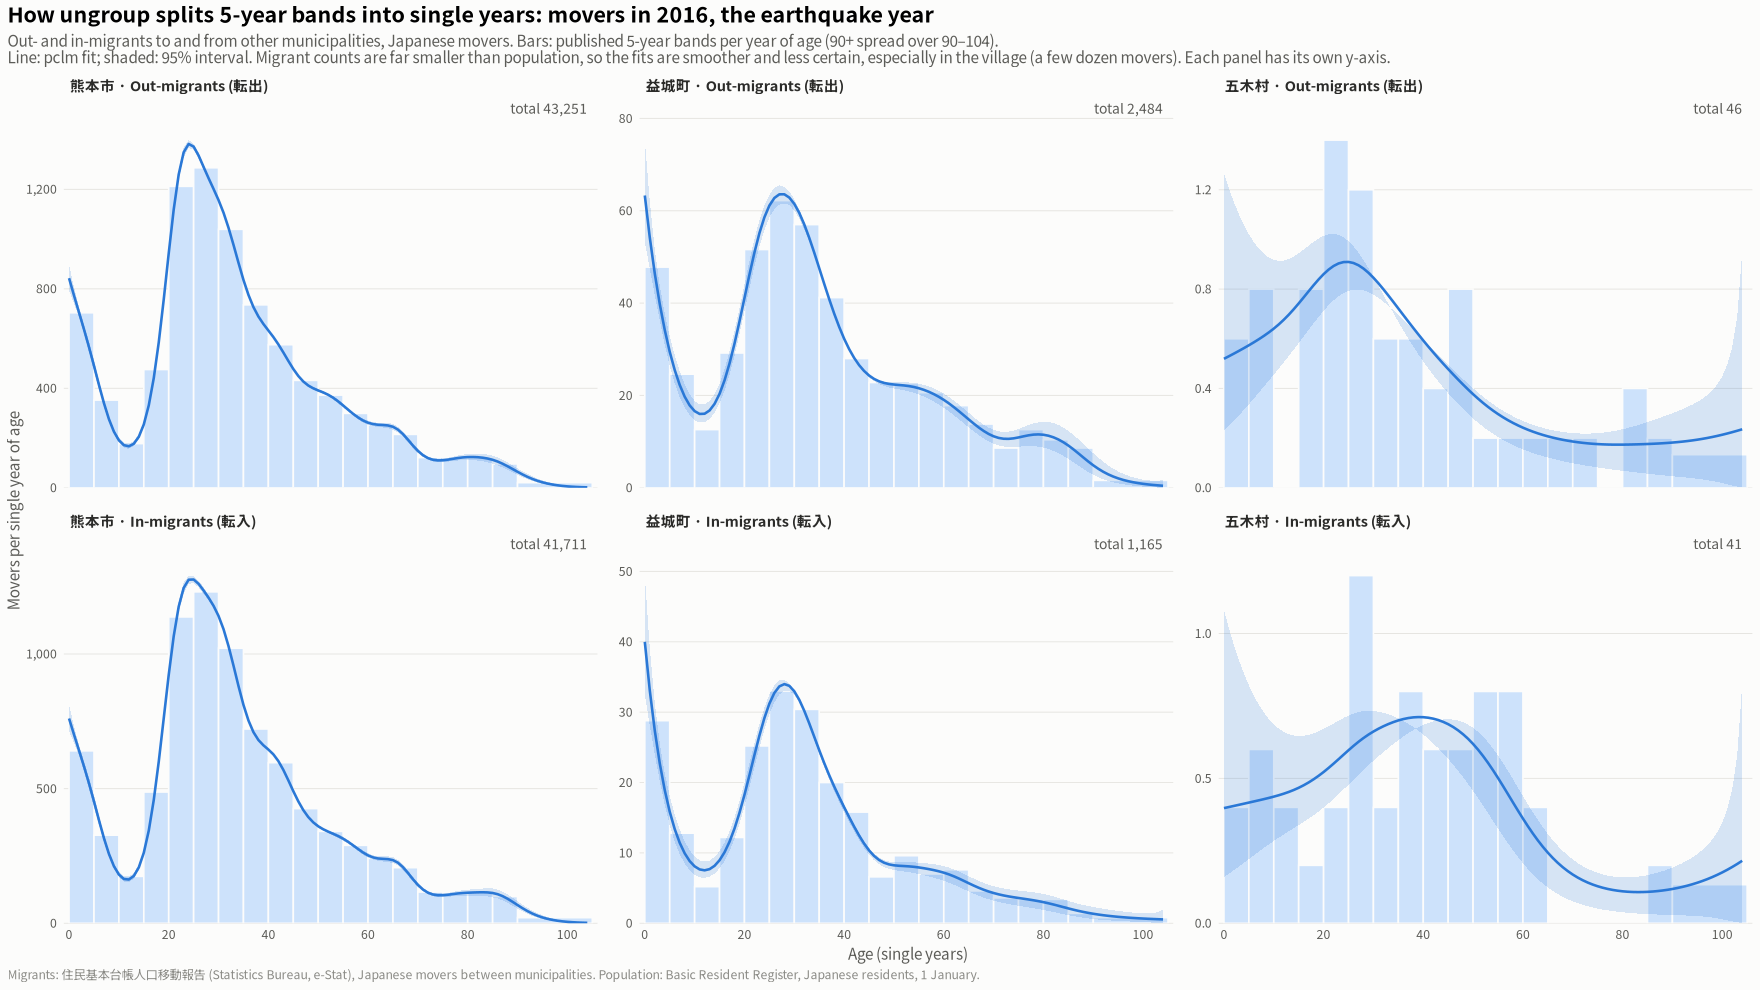

In [6]:
demo_mig2 <- demo_mig |>
  mutate(direction = ifelse(direction == "out", "Out-migrants (転出)", "In-migrants (転入)"),
         panel = factor(paste0(short, " · ", direction),
                        levels = paste0(rep(levels(showcase$short), 2), " · ",
                                        rep(c("Out-migrants (転出)", "In-migrants (転入)"), each = 3))))
show_save(
  plot_demo(demo_mig2, "panel",
            "How ungroup splits 5-year bands into single years: movers in 2016, the earthquake year",
            paste0("Out- and in-migrants to and from other municipalities, Japanese movers. Bars: published 5-year bands per year of age ",
                   "(90+ spread over 90–104).\nLine: pclm fit; shaded: 95% interval. Migrant counts are far smaller than population, ",
                   "so the fits are smoother and less certain, especially in the village (a few dozen movers). Each panel has its own y-axis."),
            "Movers per single year of age") +
    facet_wrap(~panel, ncol = 3, scales = "free_y"),
  "02_ungroup_migration", width = 16, height = 8.5)

## 2. Fitting every municipality and year

One fit per municipality × year × series (population, 転入, 転出), 2014–2025: 45 × 12 × 3 = 1,620 fits. The fits are cached. The check below compares each fit's sum with the published total: population fits are exact, and migrant fits are within about 2 movers, because pclm's Poisson fit of very sparse bands does not reproduce them exactly.

In [7]:
cache <- file.path(root, "output/3r_pclm_cache.qs2")
if (file.exists(cache)) {
  fits <- qs_read(cache)
} else {
  dir.create(dirname(cache), showWarnings = FALSE, recursive = TRUE)
  inputs <- bind_rows(pop5 |> mutate(series = "pop"),
                      mig5 |> rename(series = direction))
  t0 <- Sys.time()
  fits <- inputs |>
    group_by(code, year, series) |>
    group_modify(function(g, key) ungroup_bands(g$age_band, g$n)) |>
    ungroup()
  message("pclm fits: ", n_distinct(paste(fits$code, fits$year, fits$series)),
          " in ", round(as.numeric(difftime(Sys.time(), t0, units = "mins")), 1), " min")
  qs_save(fits, cache)
}

# Check: single-year sums vs the published totals
bind_rows(pop5 |> mutate(series = "pop"), mig5 |> rename(series = direction)) |>
  filter(age_band == "total") |>
  left_join(fits |> group_by(code, year, series) |> summarise(fit_total = sum(fit), .groups = "drop"),
            by = c("code", "year", "series")) |>
  group_by(series) |>
  summarise(fits = n(), max_abs_diff = round(max(abs(fit_total - n)), 2),
            published = sum(n), fitted = round(sum(fit_total)), .groups = "drop") |>
  as.data.frame()

series,fits,max_abs_diff,published,fitted
<chr>,<int>,<dbl>,<dbl>,<dbl>
in,540,2.27,834104,834112
out,540,1.20,869676,869680
pop,540,0.00,21084287,21084287


## 3. 5-year profiles of in- and out-migration, 熊本県, before / during / after

The published 5-year bands, without ungrouping. For each age band and period:
- **out-rate** = out-migrants ÷ population of the same band on 1 January, per 1,000 per year;
- **in-rate** is the same with in-migrants; **net** = in − out.

Each period's rate is the sum of movers ÷ the sum of 1 January populations over its years, i.e. a person-year-weighted mean.

- **Periods:** before 2014–15; the quake year 2016; after 2017–19; later 2020–25.
- **Groups:** the high-damage municipalities pooled, 熊本市, and the other 39 listed municipalities pooled.
- **Bands:** 80+ is the top band, since the 2014 population stops there.

In [8]:
to80 <- function(b) ifelse(b %in% c("80_84", "85_89", "90+", "90_94", "95_99", "100+", "80+"), "80+", b)
bands5 <- c(paste0(seq(0, 75, 5), "_", seq(4, 79, 5)), "80+")
periods <- c("Before (2014–15)", "Quake year (2016)", "After (2017–19)", "Later (2020–25)")
period_of <- function(y) factor(case_when(y <= 2015 ~ periods[1], y == 2016 ~ periods[2],
                                          y <= 2019 ~ periods[3], TRUE ~ periods[4]), levels = periods)
period_cols <- setNames(c("#8a8a85", "#eb6834", "#2a78d6", "#0d366b"), periods)

p5 <- pop5 |>
  filter(age_band != "total", !(age_band == "80+" & year >= 2015)) |>   # 80+ only where it is the top band
  mutate(band = to80(age_band)) |>
  group_by(code, year, band) |> summarise(pop = sum(n), .groups = "drop")
m5 <- mig5 |>
  filter(age_band != "total") |>
  mutate(band = to80(age_band)) |>
  group_by(code, year, band, direction) |> summarise(n = sum(n), .groups = "drop") |>
  pivot_wider(names_from = direction, values_from = n)
r5 <- p5 |>
  inner_join(m5, by = c("code", "year", "band")) |>
  left_join(study |> select(code, group), by = "code") |>
  mutate(period = period_of(year)) |>
  group_by(group, period, band) |>
  summarise(pop = sum(pop), out = sum(out), `in` = sum(`in`), .groups = "drop") |>
  mutate(`Out-migration` = 1000 * out / pop, `In-migration` = 1000 * `in` / pop,
         `Net (in − out)` = `Out-migration` * -1 + `In-migration`) |>
  pivot_longer(c(`Out-migration`, `In-migration`, `Net (in − out)`), names_to = "measure", values_to = "rate") |>
  mutate(measure = factor(measure, levels = c("Out-migration", "In-migration", "Net (in − out)")),
         group = factor(group, levels = group_levels),
         band = factor(band, levels = bands5))

# Table: rates per 1,000 for the young adult bands, high-damage group
r5 |>
  filter(group == group_levels[1], band %in% c("15_19", "20_24", "25_29", "30_34", "35_39")) |>
  mutate(rate = round(rate, 1)) |>
  select(measure, band, period, rate) |>
  pivot_wider(names_from = period, values_from = rate) |>
  arrange(measure, band) |>
  as.data.frame()

measure,band,Before (2014–15),Quake year (2016),After (2017–19),Later (2020–25)
<fct>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>
Out-migration,15_19,59.3,86.9,69.0,58.5
Out-migration,20_24,134.8,199.5,159.0,160.8
Out-migration,25_29,122.8,160.3,141.4,143.3
Out-migration,30_34,79.7,121.5,89.5,79.4
Out-migration,35_39,52.9,84.2,54.7,45.3
In-migration,15_19,47.7,42.2,40.6,40.4
In-migration,20_24,102.4,83.0,116.0,135.3
In-migration,25_29,141.1,97.3,134.0,179.4
In-migration,30_34,99.7,71.7,96.0,114.4


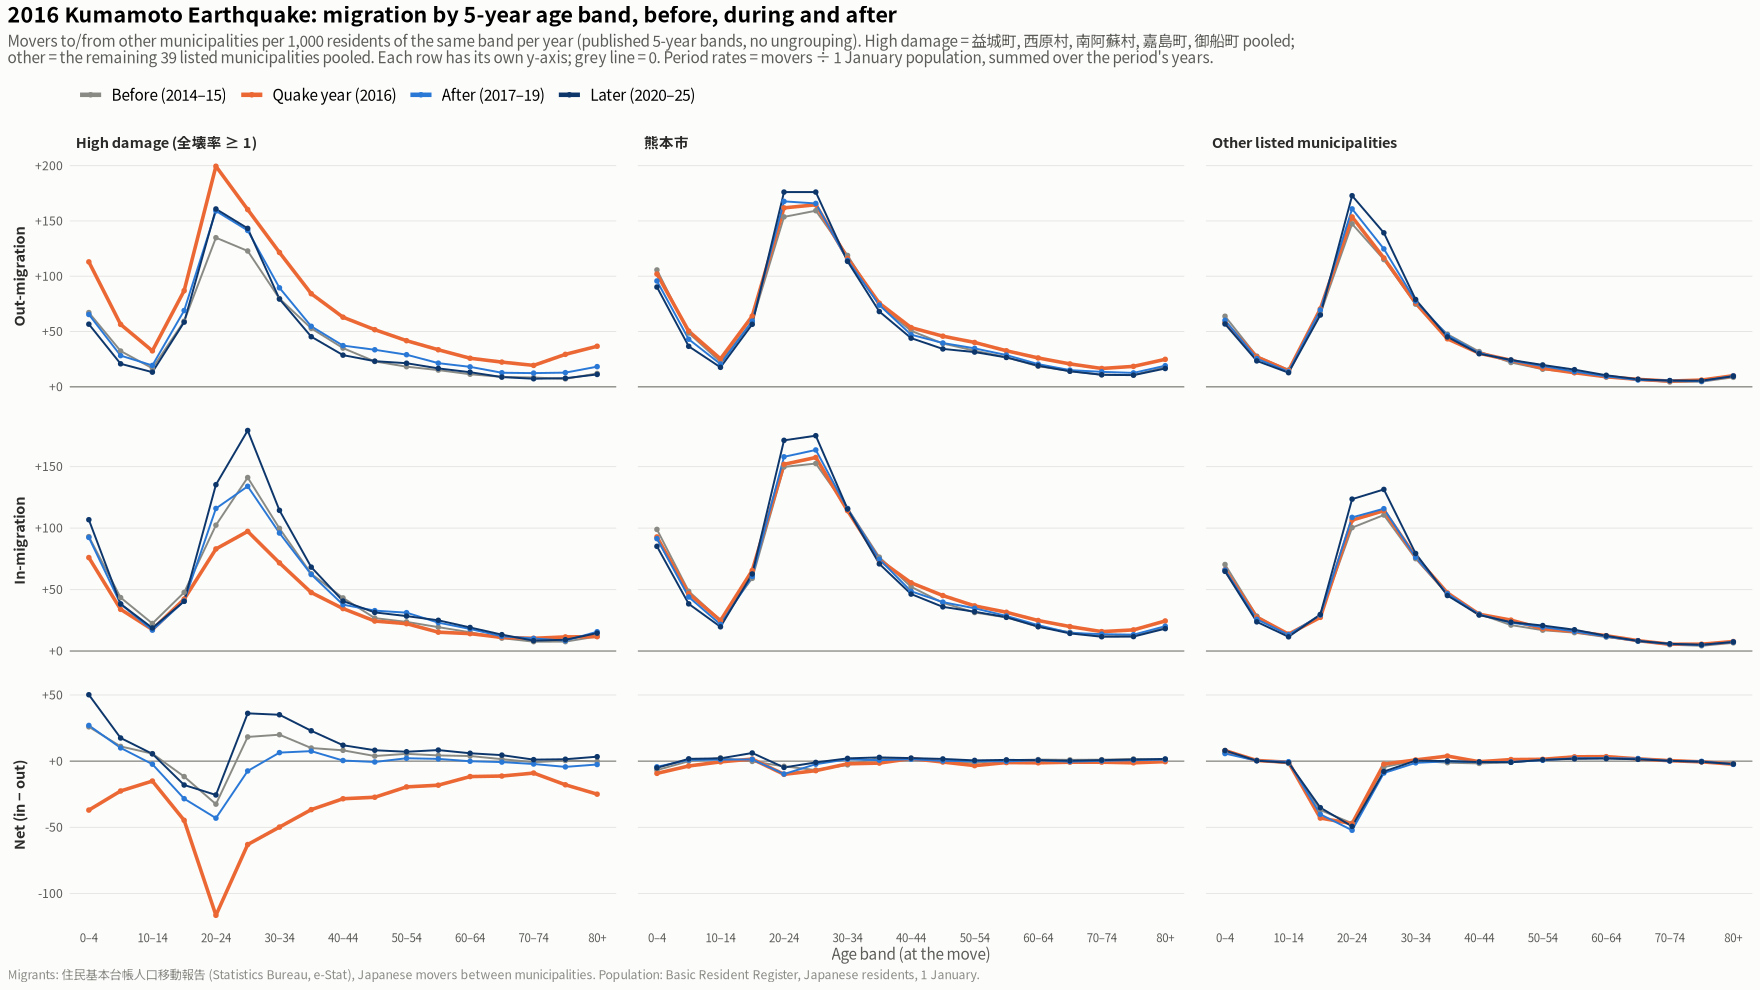

In [9]:
band_labels <- sub("_", "–", bands5)
p3 <- ggplot(r5, aes(band, rate, colour = period, group = period)) +
  geom_hline(yintercept = 0, colour = ink3, linewidth = 0.4) +
  geom_line(aes(linewidth = period == periods[2])) +
  geom_point(size = 1.1) +
  facet_grid(measure ~ group, scales = "free_y", switch = "y") +
  scale_colour_manual(values = period_cols, name = NULL) +
  scale_linewidth_manual(values = c(`FALSE` = 0.6, `TRUE` = 1.1), guide = "none") +
  scale_x_discrete(labels = function(b) ifelse(seq_along(b) %% 2 == 1, sub("_", "–", b), "")) +
  scale_y_continuous(labels = function(v) sprintf("%+g", v)) +
  labs(title = "2016 Kumamoto Earthquake: migration by 5-year age band, before, during and after",
       subtitle = paste0("Movers to/from other municipalities per 1,000 residents of the same band per year (published 5-year bands, no ungrouping). ",
                         "High damage = 益城町, 西原村, 南阿蘇村, 嘉島町, 御船町 pooled;\nother = the remaining 39 listed municipalities pooled. ",
                         "Each row has its own y-axis; grey line = 0. Period rates = movers ÷ 1 January population, summed over the period's years."),
       x = "Age band (at the move)", y = NULL, caption = src_note) +
  base_theme() +
  theme(strip.placement = "outside", strip.text.y.left = element_text(angle = 90, hjust = 0.5),
        axis.text.x = element_text(size = 7.5)) +
  guides(colour = guide_legend(override.aes = list(linewidth = 1.4)))
show_save(p3, "03_kumamoto_inout_5yr", width = 16, height = 10)

## 4. Cohort movement rates, following the 2016-01-01 age groups

From the single-year fits:

- **Population:** P(*x*, *t*) is the cohort aged *x* on 1 January of year *t*.
- **Movers:** the cohort aged *x* on 1 January *t* is credited with ½·(M(*x*, *t*) + M(*x*+1, *t*)), where M(*x*, *t*) is the movers in year *t* reported at age *x*.
- **Cohorts:** each is defined by its 5-year age group *a*…*a*+4 on 2016-01-01. In year *t* it is aged *a*+*k*…*a*+4+*k*, with *k* = *t* − 2016; 2014 and 2015 are the back-cast (*k* = −2, −1).
  - Back-cast ages below 0 (not yet born) are dropped, so the youngest cohort's 2014–15 values cover only its born members.
- **Rates:** out-rate(*t*) = Σ credited out-movers ÷ Σ P over the cohort's ages in year *t*, per 1,000; the same for in-rate. Net = in − out. **Each year uses its own 1 January denominator.**
- **Wider cohorts:** cohorts 40 and older are grouped into wider bins to keep the figure readable. The rates are pooled, i.e. movers and population are summed before dividing.

In [10]:
cohort_bins <- c(paste0(seq(0, 35, 5), "–", seq(4, 39, 5)), "40–49", "50–59", "60–69", "70–84")
cohort_of <- function(a0) {
  lab <- case_when(a0 < 40 ~ paste0(a0 %/% 5 * 5, "–", a0 %/% 5 * 5 + 4),
                   a0 < 70 ~ paste0(a0 %/% 10 * 10, "–", a0 %/% 10 * 10 + 9),
                   a0 <= 84 ~ "70–84", TRUE ~ NA_character_)
  factor(lab, levels = cohort_bins)
}

P1 <- fits |> filter(series == "pop") |> select(code, year, age, P = fit)
M1 <- fits |> filter(series != "pop") |>
  select(code, year, series, age, M = fit) |>
  group_by(code, year, series) |> arrange(age, .by_group = TRUE) |>
  # cohort aged x on 1 January gets half of the movers reported at x and x+1
  mutate(Mc = 0.5 * (M + lead(M, default = 0))) |>
  ungroup() |>
  select(-M) |>
  pivot_wider(names_from = series, values_from = Mc)

coh1 <- P1 |>
  inner_join(M1, by = c("code", "year", "age")) |>
  mutate(a0 = age - (year - base_year), cohort = cohort_of(a0)) |>   # age on 2016-01-01
  filter(a0 >= 0, !is.na(cohort)) |>
  left_join(study |> select(code, short, group), by = "code")

cohort_rates <- function(dd, ...) {
  dd |>
    group_by(..., cohort, year) |>
    summarise(P = sum(P), out = sum(out), `in` = sum(`in`), .groups = "drop") |>
    mutate(`Out-migration` = 1000 * out / P, `In-migration` = 1000 * `in` / P,
           `Net (in − out)` = `In-migration` - `Out-migration`)
}
cr_group <- cohort_rates(coh1, group) |> mutate(group = factor(group, levels = group_levels))
cr_muni  <- cohort_rates(coh1, code, short)

# Table: high-damage group, net rate per 1,000 by cohort and year
cr_group |>
  filter(group == group_levels[1]) |>
  mutate(net = round(`Net (in − out)`, 1)) |>
  select(cohort, year, net) |>
  pivot_wider(names_from = year, values_from = net) |>
  as.data.frame()

cohort,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
0–4,22.4,29.9,-36.2,11.0,15.0,20.5,18.0,14.7,13.7,11.4,7.6,4.9
5–9,11.4,14.5,-19.2,0.8,0.3,3.8,3.9,0.4,1.5,0.4,-1.9,-8.3
10–14,5.0,5.7,-16.8,-10.7,-13.6,-10.5,-16.0,-18.9,-20.2,-21.0,-22.9,-26.7
15–19,0.4,-12.2,-51.4,-39.8,-39.9,-29.3,-31.3,-14.1,-7.3,6.2,-4.4,28.2
20–24,-14.1,-39.8,-112.0,-46.9,-31.2,-2.9,17.8,26.9,44.9,61.2,27.5,44.6
25–29,0.3,6.6,-66.7,-11.9,6.8,8.4,31.3,27.3,39.9,42.6,25.1,27.2
30–34,16.1,28.7,-47.0,3.9,9.8,5.6,20.7,17.1,17.6,19.6,12.8,15.6
35–39,12.3,12.1,-35.9,2.2,0.0,9.2,13.5,14.1,5.5,9.1,7.3,11.9
40–49,8.0,6.0,-26.8,-0.8,-2.0,5.5,8.4,7.8,6.0,8.4,8.1,10.3


In [11]:
# Table: high-damage group, out-rate per 1,000 by cohort and year
cr_group |>
  filter(group == group_levels[1]) |>
  mutate(out = round(`Out-migration`, 1)) |>
  select(cohort, year, out) |>
  pivot_wider(names_from = year, values_from = out) |>
  as.data.frame()

cohort,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
0–4,72.1,63.1,103.1,47.2,41.9,31.8,24.5,20.0,18.4,18.9,15.9,17.8
5–9,37.6,32.1,51.2,24.5,29.4,21.1,22.6,24.3,26.5,30.2,32.6,45.9
10–14,25.2,24.6,44.7,34.4,45.1,45.2,59.1,71.3,86.3,94.8,109.0,137.3
15–19,40.8,56.3,95.0,90.9,106.8,124.9,144.6,148.6,162.5,163.1,165.9,152.7
20–24,97.1,132.2,192.6,152.3,165.3,162.7,149.4,142.4,123.7,114.7,106.3,86.4
25–29,129.3,132.7,162.6,120.3,118.8,116.0,89.5,81.1,63.7,59.2,54.3,46.0
30–34,96.4,85.0,117.0,73.0,71.5,68.6,51.7,45.7,37.5,34.8,31.5,29.6
35–39,57.6,58.0,82.8,44.8,50.0,39.5,32.1,28.5,29.8,24.9,23.4,22.5
40–49,31.3,31.8,56.3,32.2,34.6,31.3,24.0,20.5,22.0,19.6,19.8,18.8


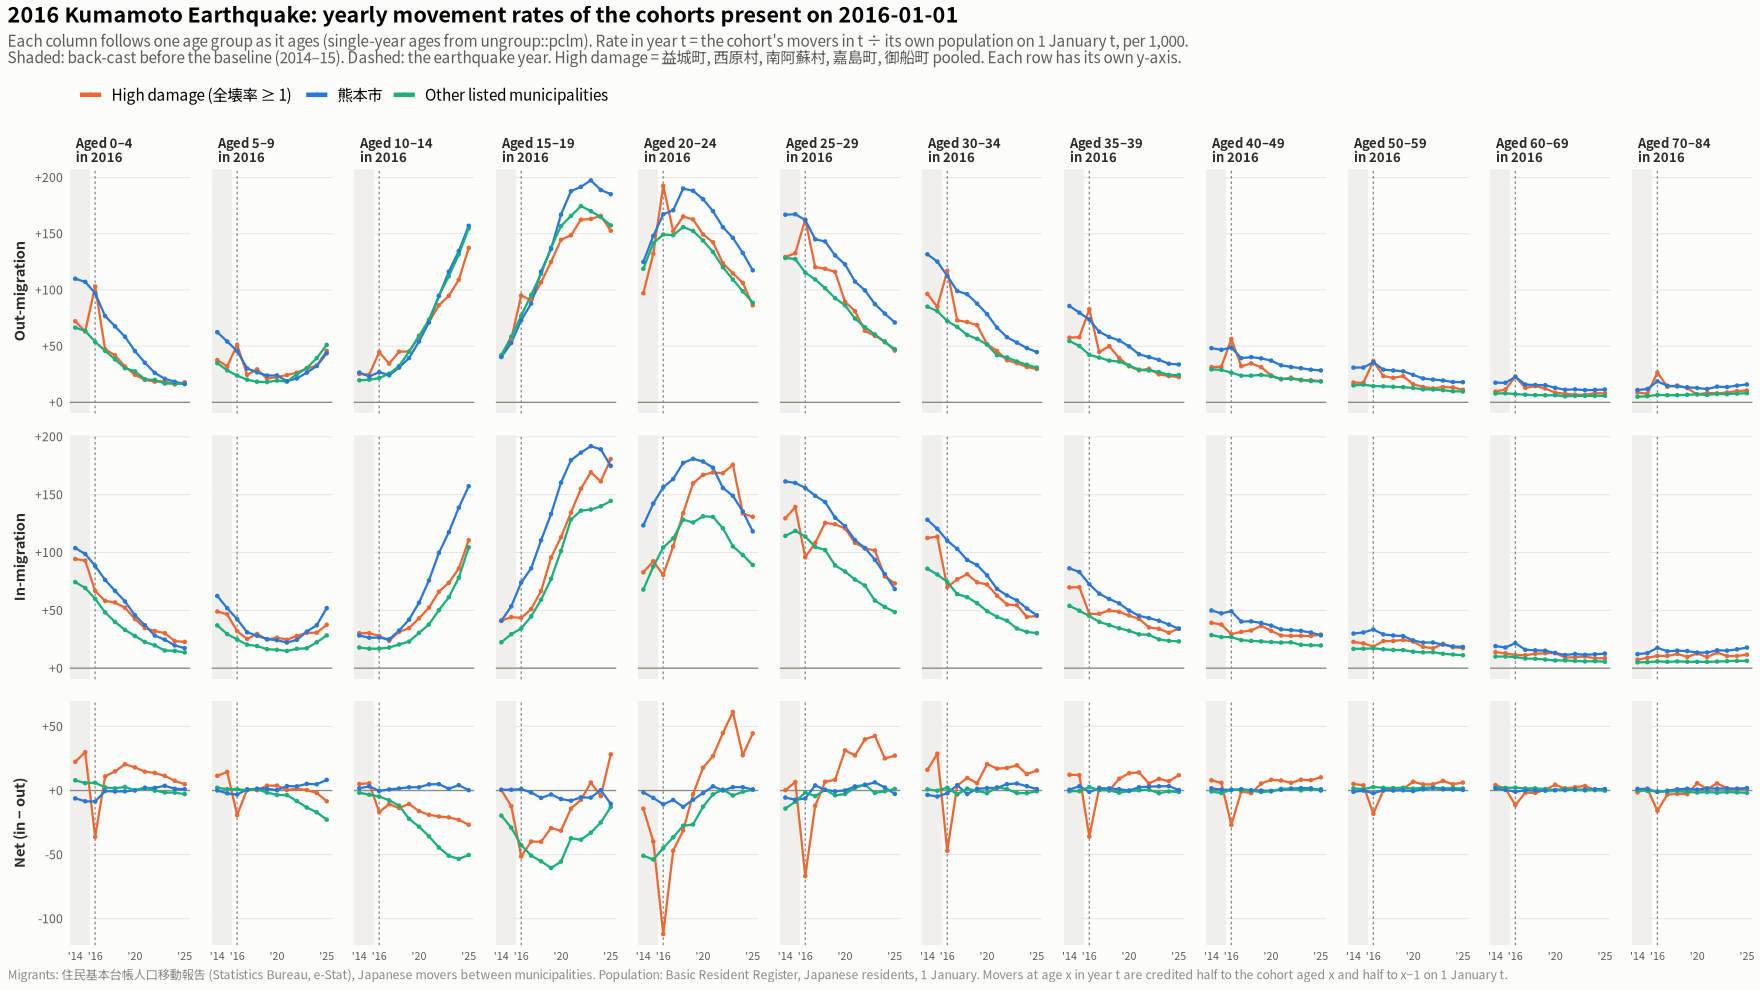

In [12]:
cr_long <- cr_group |>
  pivot_longer(c(`Out-migration`, `In-migration`, `Net (in − out)`), names_to = "measure", values_to = "rate") |>
  mutate(measure = factor(measure, levels = c("Out-migration", "In-migration", "Net (in − out)")),
         cohort_lab = factor(paste0("Aged ", cohort, "\nin 2016"), levels = paste0("Aged ", cohort_bins, "\nin 2016")))

p4 <- ggplot(cr_long, aes(year, rate, colour = group)) +
  annotate("rect", xmin = -Inf, xmax = base_year - 0.5, ymin = -Inf, ymax = Inf, fill = "#f0efec") +
  geom_hline(yintercept = 0, colour = ink3, linewidth = 0.4) +
  geom_vline(xintercept = event_x, colour = ink3, linewidth = 0.4, linetype = "22") +
  geom_line(linewidth = 0.7) +
  geom_point(size = 0.8) +
  facet_grid(measure ~ cohort_lab, scales = "free_y", switch = "y") +
  scale_colour_manual(values = group_cols, name = NULL) +
  scale_x_continuous(breaks = c(2014, 2016, 2020, 2025), labels = c("'14", "'16", "'20", "'25")) +
  scale_y_continuous(labels = function(v) sprintf("%+g", v)) +
  labs(title = "2016 Kumamoto Earthquake: yearly movement rates of the cohorts present on 2016-01-01",
       subtitle = paste0("Each column follows one age group as it ages (single-year ages from ungroup::pclm). Rate in year t = the cohort's movers in t ÷ its own population on 1 January t, ",
                         "per 1,000.\nShaded: back-cast before the baseline (2014–15). Dashed: the earthquake year. ",
                         "High damage = 益城町, 西原村, 南阿蘇村, 嘉島町, 御船町 pooled. Each row has its own y-axis."),
       x = NULL, y = NULL,
       caption = paste0(src_note, " Movers at age x in year t are credited half to the cohort aged x and half to x−1 on 1 January t.")) +
  base_theme() +
  theme(strip.placement = "outside", strip.text.y.left = element_text(angle = 90, hjust = 0.5),
        strip.text.x = element_text(size = 8.5), axis.text.x = element_text(size = 7)) +
  guides(colour = guide_legend(override.aes = list(linewidth = 1.4)))
show_save(p4, "04_cohort_rates_groups", width = 20, height = 10)

### Net cohort rates per municipality (figures 5–7)

The same net rate (in − out per 1,000), cohort × year, for **all 45 listed municipalities**, with the original 5-year cohorts.

- **Layout:** 15 municipalities per figure, ordered by 全壊率, highest first.
- **Panel titles:** 全壊率 and the population on 2016-01-01 (Japanese residents, the denominator basis used here).
- **Colour:** orange = net loss, blue = net gain, grey ≈ 0. The scale is capped at ±60 per 1,000, so the darkest cells may be larger.
- **Small municipalities:** in the smallest villages a cohort can be a few dozen people and the single-year split is a smooth guess (see figures 1–2), so single cells are noisy. Read the broad patterns only.
- **Other disasters:** the July 2020 Kyushu floods (令和2年7月豪雨) hit the Kuma river basin (球磨村, 人吉市, 芦北町, 八代市 among the listed municipalities). The broad losses in 球磨村 from 2020 are from the floods, not the earthquake.

In [13]:
pop_base <- pop5 |> filter(year == base_year, age_band == "total") |> select(code, pop_2016 = n)

coh5 <- coh1 |>
  filter(a0 <= 84) |>
  mutate(cohort = factor(paste0(a0 %/% 5 * 5, "–", a0 %/% 5 * 5 + 4),
                         levels = paste0(seq(0, 80, 5), "–", seq(4, 84, 5)))) |>
  group_by(code, short, cohort, year) |>
  summarise(net = 1000 * (sum(`in`) - sum(out)) / sum(P), .groups = "drop")

# Panel order and labels: 全壊率 (highest first), then population
panel_tbl <- study |>
  left_join(pop_base, by = "code") |>
  arrange(desc(zenkai_rate), desc(pop_2016)) |>
  mutate(rank = row_number(),
         figure = (rank - 1) %/% 15 + 1,
         label = sprintf("%s\n全壊率 %.2f · pop. %s", short, zenkai_rate, scales::comma(pop_2016)))
coh5 <- coh5 |>
  left_join(panel_tbl |> select(code, rank, figure, label), by = "code") |>
  mutate(label = factor(label, levels = panel_tbl$label))

panel_tbl |> select(figure, rank, municipality = short, `全壊率` = zenkai_rate, pop_2016) |>
  mutate(`全壊率` = round(`全壊率`, 2)) |> as.data.frame()

figure,rank,municipality,全壊率,pop_2016
<dbl>,<int>,<chr>,<dbl>,<dbl>
1,1,益城町,8.75,34503
1,2,西原村,7.25,7037
1,3,南阿蘇村,5.98,11649
1,4,嘉島町,2.54,9196
1,5,御船町,2.51,17665
1,6,甲佐町,0.94,11082
1,7,宇城市,0.89,60634
1,8,産山村,0.75,1566
1,9,大津町,0.45,33904


In [14]:
cap <- 60
plot_net_heat <- function(k) {
  dd <- coh5 |> filter(figure == k)
  ranks <- range(dd$rank)
  ggplot(dd, aes(year, cohort, fill = pmax(pmin(net, cap), -cap))) +
    geom_tile(colour = surface, linewidth = 0.3) +
    geom_vline(xintercept = event_x - 0.5, colour = ink, linewidth = 0.4, linetype = "22") +
    facet_wrap(~label, ncol = 5) +
    scale_fill_gradient2(low = "#eb6834", mid = "#f0efec", high = "#2a78d6", midpoint = 0,
                         limits = c(-cap, cap), breaks = seq(-cap, cap, 20),
                         labels = function(v) ifelse(abs(v) == cap, sprintf("%+g or beyond", v), sprintf("%+g", v)),
                         name = "Net per 1,000") +
    scale_x_continuous(breaks = c(2014, 2016, 2020, 2025), expand = c(0, 0)) +
    scale_y_discrete(expand = c(0, 0), labels = function(l) ifelse(seq_along(l) %% 2 == 1, l, "")) +
    labs(title = sprintf("Net migration rate of each 2016-01-01 cohort, by year: listed Kumamoto municipalities %d–%d of 45 (by 全壊率)",
                         ranks[1], ranks[2]),
         subtitle = paste0("Rows: age group on 2016-01-01, followed as it ages. Columns: calendar year (2014–15 back-cast). ",
                           "Net = (in − out) movers in the year ÷ the cohort's 1 January population, per 1,000.\n",
                           "Panel titles: 全壊率 (fully destroyed buildings per 100 residents) and population on 2016-01-01 (Japanese residents). ",
                           "Dashed line: start of the earthquake year 2016. Small municipalities are noisy; read broad patterns only."),
         x = NULL, y = "Age on 2016-01-01", caption = src_note) +
    base_theme() +
    theme(panel.grid.major.y = element_blank(), legend.position = "right",
          legend.justification = "center", legend.key.height = unit(1.4, "cm"),
          strip.text = element_text(face = "bold", hjust = 0, colour = ink, size = 9, lineheight = 1.1),
          axis.text.x = element_text(size = 7.5), axis.text.y = element_text(size = 7))
}

### Figure 5: municipalities 1–15 by 全壊率

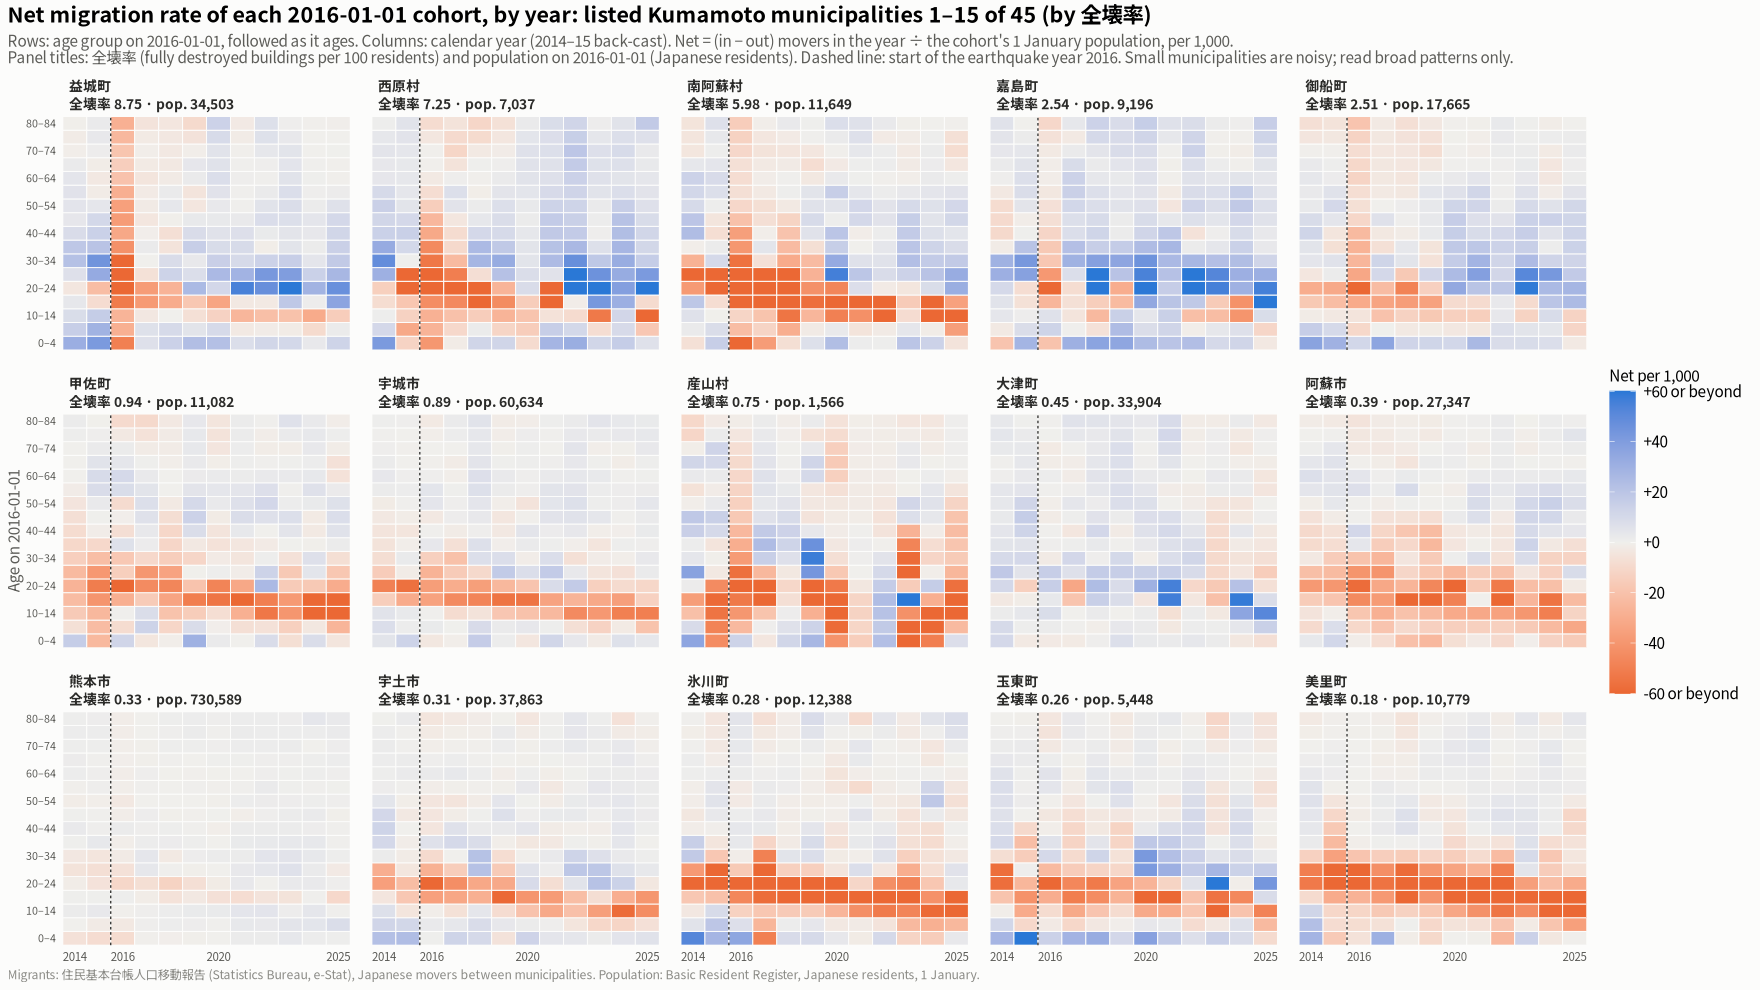

In [15]:
show_save(plot_net_heat(1), "05_cohort_net_rate_1", width = 18, height = 12)

### Figure 6: municipalities 16–30 by 全壊率

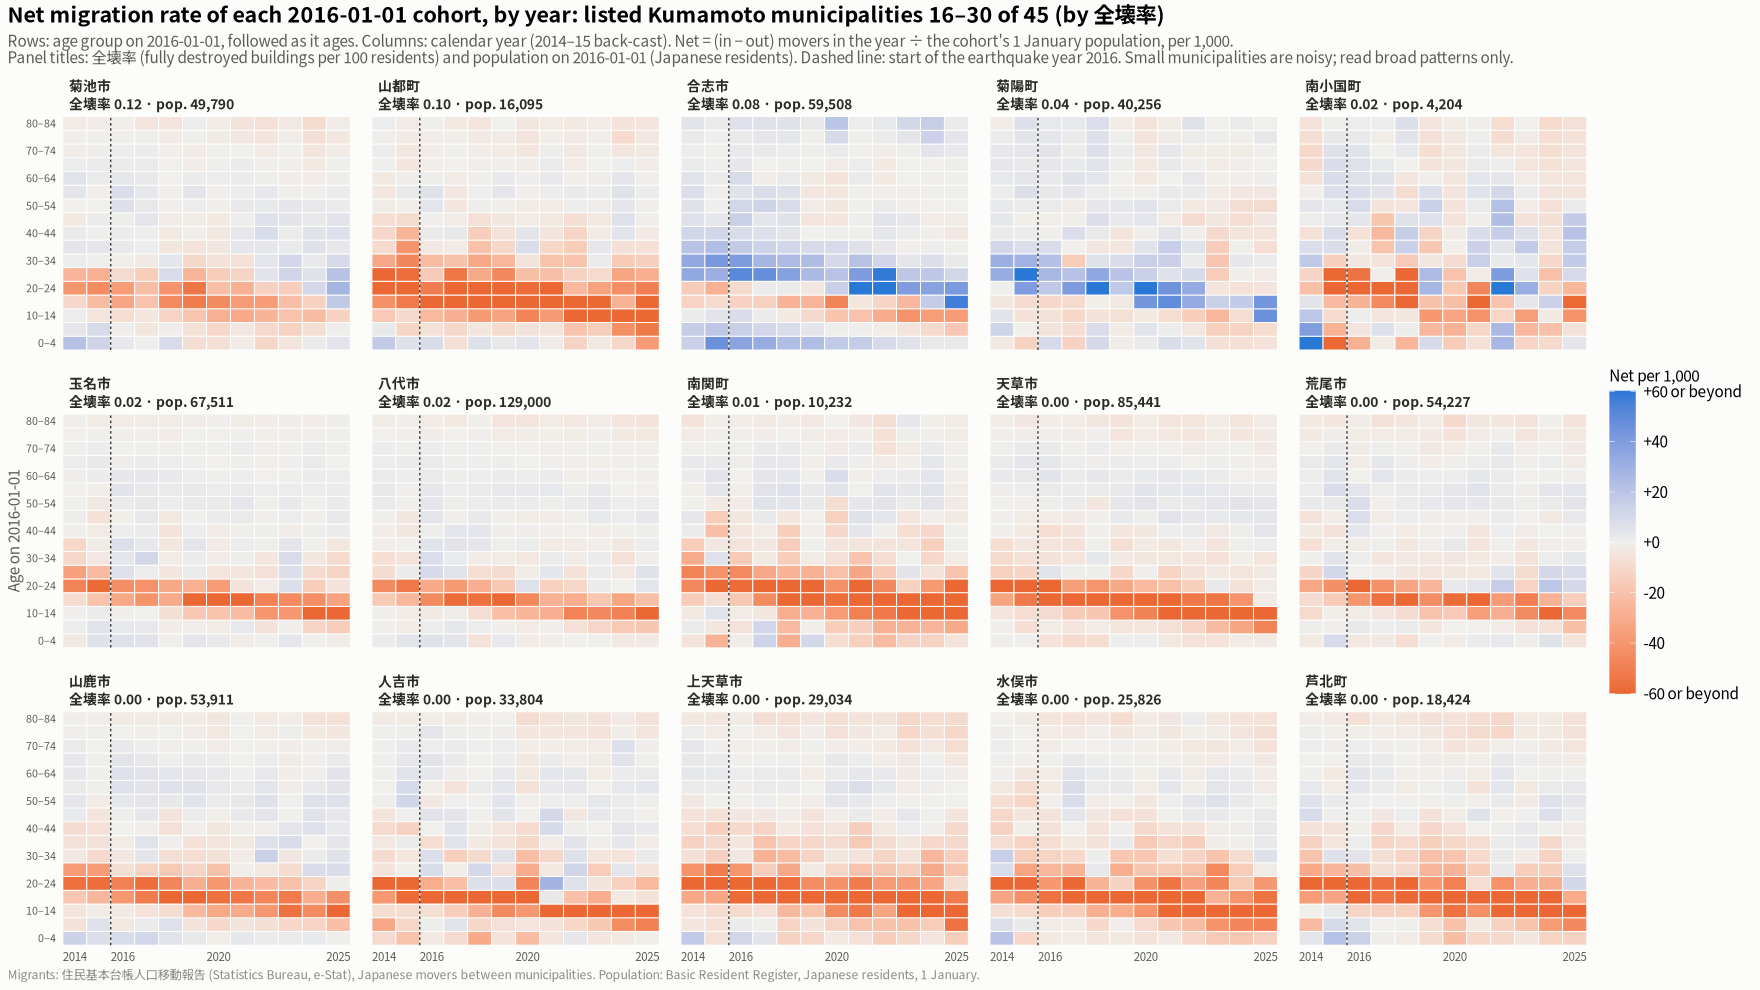

In [16]:
show_save(plot_net_heat(2), "06_cohort_net_rate_2", width = 18, height = 12)

### Figure 7: municipalities 31–45 by 全壊率

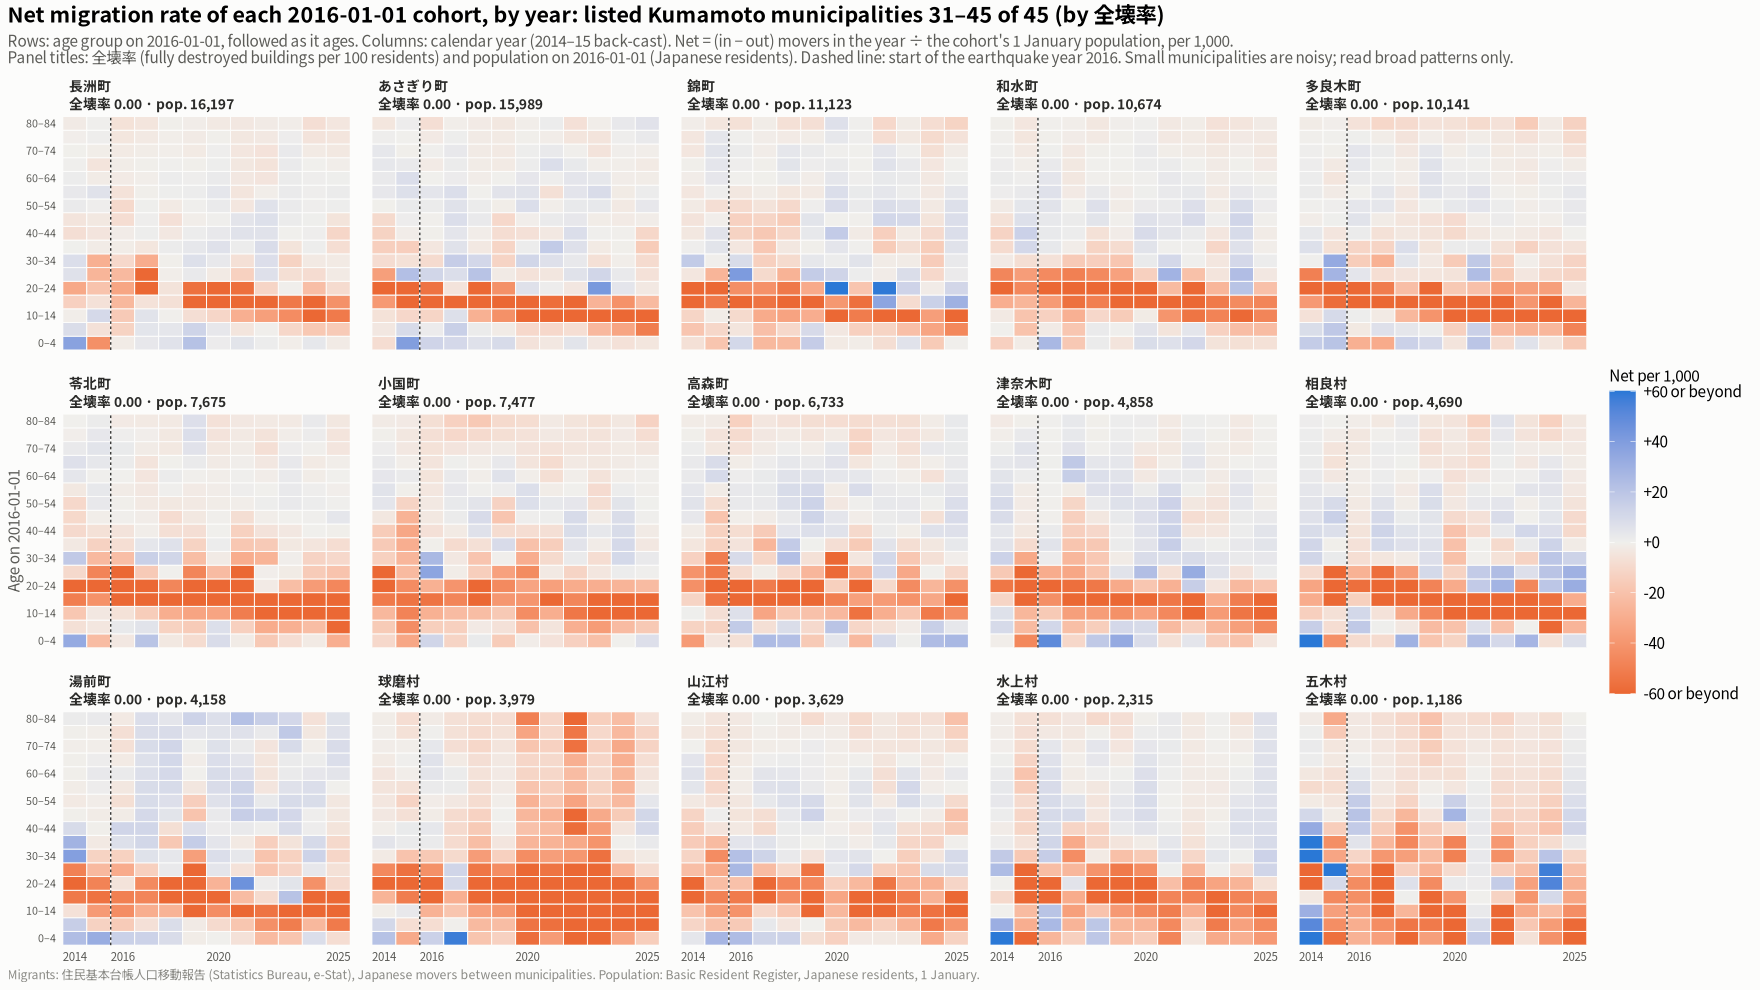

In [17]:
show_save(plot_net_heat(3), "07_cohort_net_rate_3", width = 18, height = 12)

## 5. Change in net migration from the pre-quake baseline, by age band

The published 5-year bands, as in section 3 (no ungrouping; top band 80+). For group *g*, band *b* and calendar year *t*:

- **Net rate:** rate(*g*, *b*, *t*) = 1000 · (Σ in − Σ out) ÷ Σ 1 January population, pooled over the group's municipalities.
- **Baseline:** base(*g*, *b*) is the mean of the band's 2014 and 2015 net rates: (rate<sub>2014</sub> + rate<sub>2015</sub>) / 2.
- **Change** = rate − base, in points per 1,000 per year. Negative means the band lost more, or gained less, than before the quake. Used in figures 9–10.

**Figure 8: diverging stacked bars.** Band rates have different denominators, so they cannot be stacked into a total. Figure 8 instead stacks each band's **contribution** to the group's all-ages rate:

- contrib(*g*, *b*, *t*) = 1000 · (Σ in − Σ out)<sub>*b*</sub> ÷ Σ 1 January population of **all ages**, minus the same quantity's 2014–15 mean.
- Bars above 0 stack the bands whose contribution rose; bars below 0 stack those whose contribution fell.
- The bands add up exactly to the change in the all-ages net rate, shown as a dashed line.

The 2014 and 2015 values are shown too. By construction they are equal and opposite (±half the 2014–15 difference), so their spread is a rough guide to year-to-year noise. Groups are those of sections 3–4. In "Other listed", changes from 2020 include the July 2020 Kuma river floods (球磨村, 人吉市, 芦北町, 八代市).


In [18]:
yr5 <- p5 |>
  inner_join(m5, by = c("code", "year", "band")) |>
  left_join(study |> select(code, group), by = "code") |>
  group_by(group, band, year) |>
  summarise(pop = sum(pop), net = sum(`in`) - sum(out), .groups = "drop")
base5 <- yr5 |>
  filter(year <= 2015) |>
  group_by(group, band) |>
  summarise(base = mean(1000 * net / pop), .groups = "drop")   # mean of the 2014 and 2015 rates
chg5 <- yr5 |>
  left_join(base5, by = c("group", "band")) |>
  mutate(rate = 1000 * net / pop, change = rate - base,
         group = factor(group, levels = group_levels),
         band = factor(band, levels = bands5))

# Table: change from baseline (per 1,000), high-damage group, young adult bands
chg5 |>
  filter(group == group_levels[1], band %in% c("15_19", "20_24", "25_29", "30_34", "35_39")) |>
  mutate(change = round(change, 1)) |>
  select(band, year, change) |>
  pivot_wider(names_from = year, values_from = change) |>
  left_join(base5 |> filter(group == group_levels[1]) |> transmute(band, baseline = round(base, 1)), by = "band") |>
  as.data.frame()


band,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,baseline
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
15_19,6.9,-6.9,-33.0,-18.6,-20.3,-10.9,-15.6,-10.6,-7.3,-4.2,3.3,-4.3,-11.7
20_24,10.0,-10.0,-84.0,-21.8,-12.3,2.9,3.9,13.5,15.6,10.2,-2.6,0.7,-32.4
25_29,-1.4,1.4,-81.3,-40.6,-26.5,-8.2,7.3,13.0,16.5,35.3,3.2,31.4,18.3
30_34,-7.5,7.5,-69.8,-17.6,-9.0,-13.8,8.5,6.3,25.5,30.1,5.4,15.1,20.0
35_39,1.8,-1.8,-46.5,-3.5,-0.1,-3.4,8.5,6.4,14.1,21.8,9.7,18.0,9.9


group,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
High damage (全壊率 ≥ 1),0.2,-0.2,-34.1,-8.8,-6.3,-2.0,4.5,3.4,6.1,7.7,2.4,5.2
熊本市,0.2,-0.2,-1.7,0.6,-0.5,0.2,0.0,1.2,1.8,2.3,2.3,0.5
Other listed municipalities,0.4,-0.4,0.6,-0.3,0.2,-1.0,-0.7,1.4,0.8,-0.6,-0.2,0.2


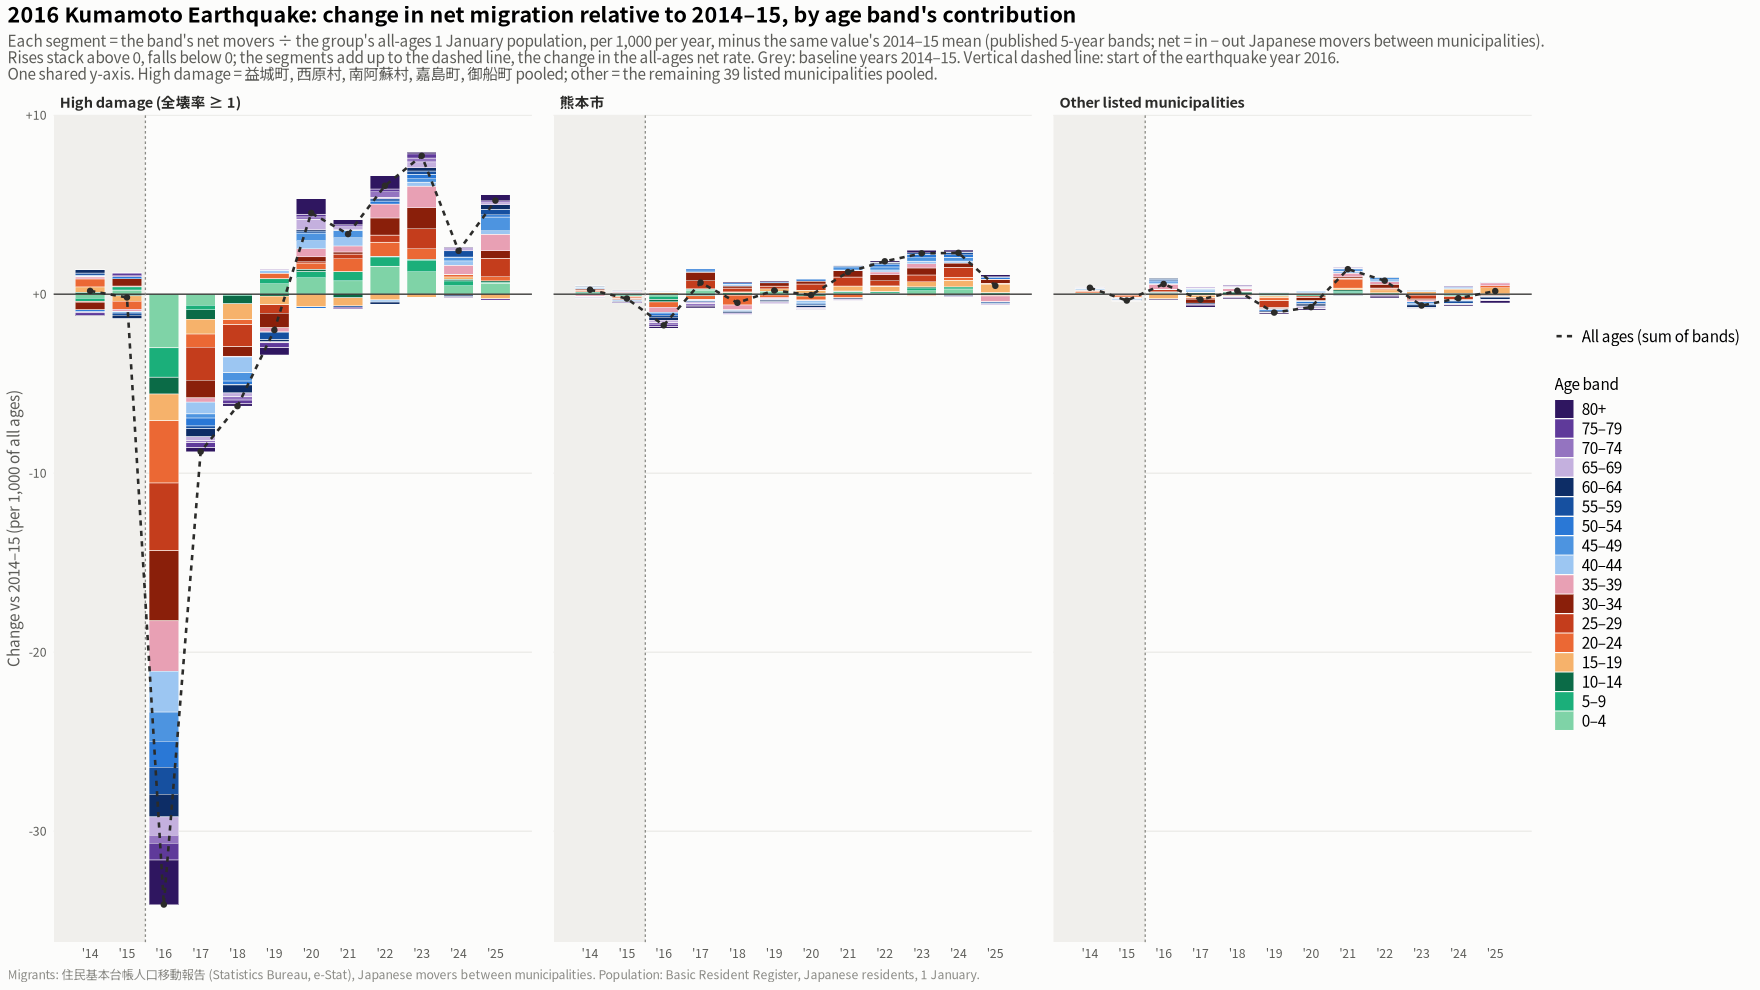

In [19]:
# Diverging fill capped at +-cap; labels mark the capped ends (used in figure 9)
change_fill <- function(cap, name) {
  scale_fill_gradient2(low = "#eb6834", mid = "#f0efec", high = "#2a78d6", midpoint = 0,
                       limits = c(-cap, cap), breaks = seq(-cap, cap, cap / 2),
                       labels = function(v) ifelse(abs(v) == cap, sprintf("%+g or beyond", v), sprintf("%+g", v)),
                       name = name)
}
heat_theme <- function() list(
  base_theme(),
  theme(panel.grid.major.y = element_blank(), legend.position = "right",
        legend.justification = "center", legend.key.height = unit(1.4, "cm"),
        axis.text.x = element_text(size = 7.5), axis.text.y = element_text(size = 7.5))
)

# Colour = life stage (hue family), shade = band within it (also used in figure 10)
band_family <- list(
  `0–14`  = c("#7fd3a7", "#1baf7a", "#0b6b47"),                          # greens
  `15–39` = c("#f6b26b", "#eb6834", "#c43d1c", "#8a1f0a", "#e8a0b4"),    # oranges / reds
  `40–64` = c("#9cc6f2", "#4d94e0", "#2a78d6", "#1650a0", "#0d2d66"),    # blues
  `65+`   = c("#c4b0de", "#9474c0", "#5f3a9a", "#2f1660"))              # purples
band_cols <- setNames(unlist(band_family, use.names = FALSE), bands5)
stopifnot(length(band_cols) == length(bands5))

# Each band's contribution to the all-ages net rate: band net / all-ages population
contrib5 <- yr5 |>
  group_by(group, year) |>
  mutate(pop_all = sum(pop)) |>
  ungroup() |>
  mutate(contrib = 1000 * net / pop_all) |>
  group_by(group, band) |>
  mutate(change = contrib - mean(contrib[year <= 2015])) |>   # minus the mean of its 2014 and 2015 values
  ungroup() |>
  mutate(group = factor(group, levels = group_levels), band = factor(band, levels = bands5))
tot5 <- contrib5 |> group_by(group, year) |> summarise(change = sum(change), .groups = "drop")

# Check: bands add up to the change in the all-ages rate
chk <- yr5 |> group_by(group, year) |> summarise(rate = 1000 * sum(net) / sum(pop), .groups = "drop") |>
  group_by(group) |> mutate(change_all = rate - mean(rate[year <= 2015])) |> ungroup() |>
  mutate(group = factor(group, levels = group_levels)) |>
  inner_join(tot5, by = c("group", "year"))
stopifnot(max(abs(chk$change_all - chk$change)) < 1e-9)

# Table: change in the all-ages net rate (per 1,000), by group
tot5 |> mutate(change = round(change, 1)) |> pivot_wider(names_from = year, values_from = change) |> as.data.frame()

p8 <- ggplot(contrib5, aes(year, change)) +
  annotate("rect", xmin = -Inf, xmax = base_year - 0.5, ymin = -Inf, ymax = Inf, fill = "#f0efec") +
  geom_col(aes(fill = band), width = 0.8, colour = surface, linewidth = 0.15,
           position = position_stack(reverse = TRUE)) +  # youngest band next to zero, oldest outermost
  geom_hline(yintercept = 0, colour = ink, linewidth = 0.4) +
  geom_vline(xintercept = event_x - 0.5, colour = ink3, linewidth = 0.4, linetype = "22") +
  geom_line(data = tot5, aes(linetype = "All ages (sum of bands)"), colour = ink, linewidth = 0.8) +
  geom_point(data = tot5, colour = ink, size = 1.4) +
  facet_wrap(~group, nrow = 1) +
  scale_fill_manual(values = band_cols, labels = function(b) sub("_", "–", b), name = "Age band",
                    guide = guide_legend(ncol = 1, reverse = TRUE, order = 2)) +
  scale_linetype_manual(values = c("All ages (sum of bands)" = "22"), name = NULL,
                        guide = guide_legend(order = 1, override.aes = list(linewidth = 0.8))) +
  scale_x_continuous(breaks = years, labels = function(v) paste0("'", substr(v, 3, 4))) +
  scale_y_continuous(labels = function(v) sprintf("%+g", v)) +
  labs(title = "2016 Kumamoto Earthquake: change in net migration relative to 2014–15, by age band's contribution",
       subtitle = paste0("Each segment = the band's net movers ÷ the group's all-ages 1 January population, per 1,000 per year, minus the same value's 2014–15 mean ",
                         "(published 5-year bands; net = in − out Japanese movers between municipalities).\n",
                         "Rises stack above 0, falls below 0; the segments add up to the dashed line, the change in the all-ages net rate. ",
                         "Grey: baseline years 2014–15. Vertical dashed line: start of the earthquake year 2016.\n",
                         "One shared y-axis. High damage = 益城町, 西原村, 南阿蘇村, 嘉島町, 御船町 pooled; other = the remaining 39 listed municipalities pooled."),
       x = NULL, y = "Change vs 2014–15 (per 1,000 of all ages)", caption = src_note) +
  base_theme() +
  theme(legend.position = "right", legend.justification = "center", legend.key.size = unit(0.45, "cm"))
show_save(p8, "08_band_change_stacked", width = 18, height = 7.5)


### Figure 9: change from baseline per municipality, every age band

The same change, for every published 5-year band (0–4 … 75–79, 80+), in **every listed municipality**. Each municipality is compared with **its own** 2014–15 reference for that band: the mean of its 2014 and 2015 net rates.

- **Rows:** municipalities ordered by 全壊率, highest first, within the 3r groups. The label shows 全壊率.
- **Colour:** capped at ±60 per 1,000.
- **Small municipalities:** in the smallest villages a band is a few dozen people, so one or two movers shift a cell by tens per 1,000. The table below gives each band's population on 2016-01-01. Cells with no residents in the band are grey. Read patterns that persist over years, not single cells.


In [20]:
focus_bands <- bands5   # every published band
mun5 <- p5 |>
  inner_join(m5, by = c("code", "year", "band")) |>
  filter(band %in% focus_bands) |>
  mutate(net = `in` - out) |>
  group_by(code, band) |>
  mutate(rate = ifelse(pop > 0, 1000 * net / pop, NA),
         base = mean(rate[year <= 2015]),   # mean of the 2014 and 2015 rates
         change = rate - base) |>
  ungroup() |>
  left_join(panel_tbl |> select(code, short, zenkai_rate, rank), by = "code") |>
  left_join(study |> select(code, group), by = "code") |>
  mutate(group = factor(group, levels = group_levels),
         band = factor(sub("_", "–", band), levels = sub("_", "–", focus_bands)))
row_lab <- panel_tbl |> arrange(rank) |> mutate(lab = sprintf("%s  %.2f", short, zenkai_rate))
mun5 <- mun5 |> mutate(row = factor(sprintf("%s  %.2f", short, zenkai_rate), levels = rev(row_lab$lab)))

# Table: band population on 2016-01-01, per municipality
mun5 |>
  filter(year == base_year) |>
  select(rank, municipality = short, `全壊率` = zenkai_rate, band, pop) |>
  left_join(mun5 |> distinct(short, band, base) |> rename(municipality = short), by = c("municipality", "band")) |>
  mutate(`全壊率` = round(`全壊率`, 2), base = round(base, 1)) |>
  select(-base) |>
  pivot_wider(names_from = band, values_from = pop) |>
  arrange(rank) |>
  as.data.frame()


rank,municipality,全壊率,0–4,10–14,15–19,20–24,25–29,30–34,35–39,40–44,45–49,50–54,55–59,5–9,60–64,65–69,70–74,75–79,80+
<int>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,益城町,8.75,1822,1720,1624,1449,1710,2175,2242,2268,1855,1952,2230,1850,2572,2677,1748,1639,2970
2,西原村,7.25,317,356,306,229,326,396,401,471,392,442,508,374,596,560,327,312,724
3,南阿蘇村,5.98,397,475,493,521,378,477,537,668,541,693,868,431,1068,1139,756,724,1483
4,嘉島町,2.54,565,405,435,438,478,566,648,606,543,507,533,477,610,623,450,455,857
5,御船町,2.51,714,706,766,747,776,905,1006,1024,852,1036,1207,820,1510,1586,1064,960,1986
6,甲佐町,0.94,441,432,424,434,396,566,570,600,511,622,728,480,897,1007,691,723,1560
7,宇城市,0.89,2520,2726,2795,2545,2736,3128,3442,3514,3310,3726,3999,2649,4822,4999,3636,3381,6706
8,産山村,0.75,53,62,55,61,51,53,64,57,96,97,103,67,134,133,92,121,267
9,大津町,0.45,2108,1721,1728,1679,2148,2511,2435,2380,1937,2040,2083,2071,2109,2040,1287,1194,2433


Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.


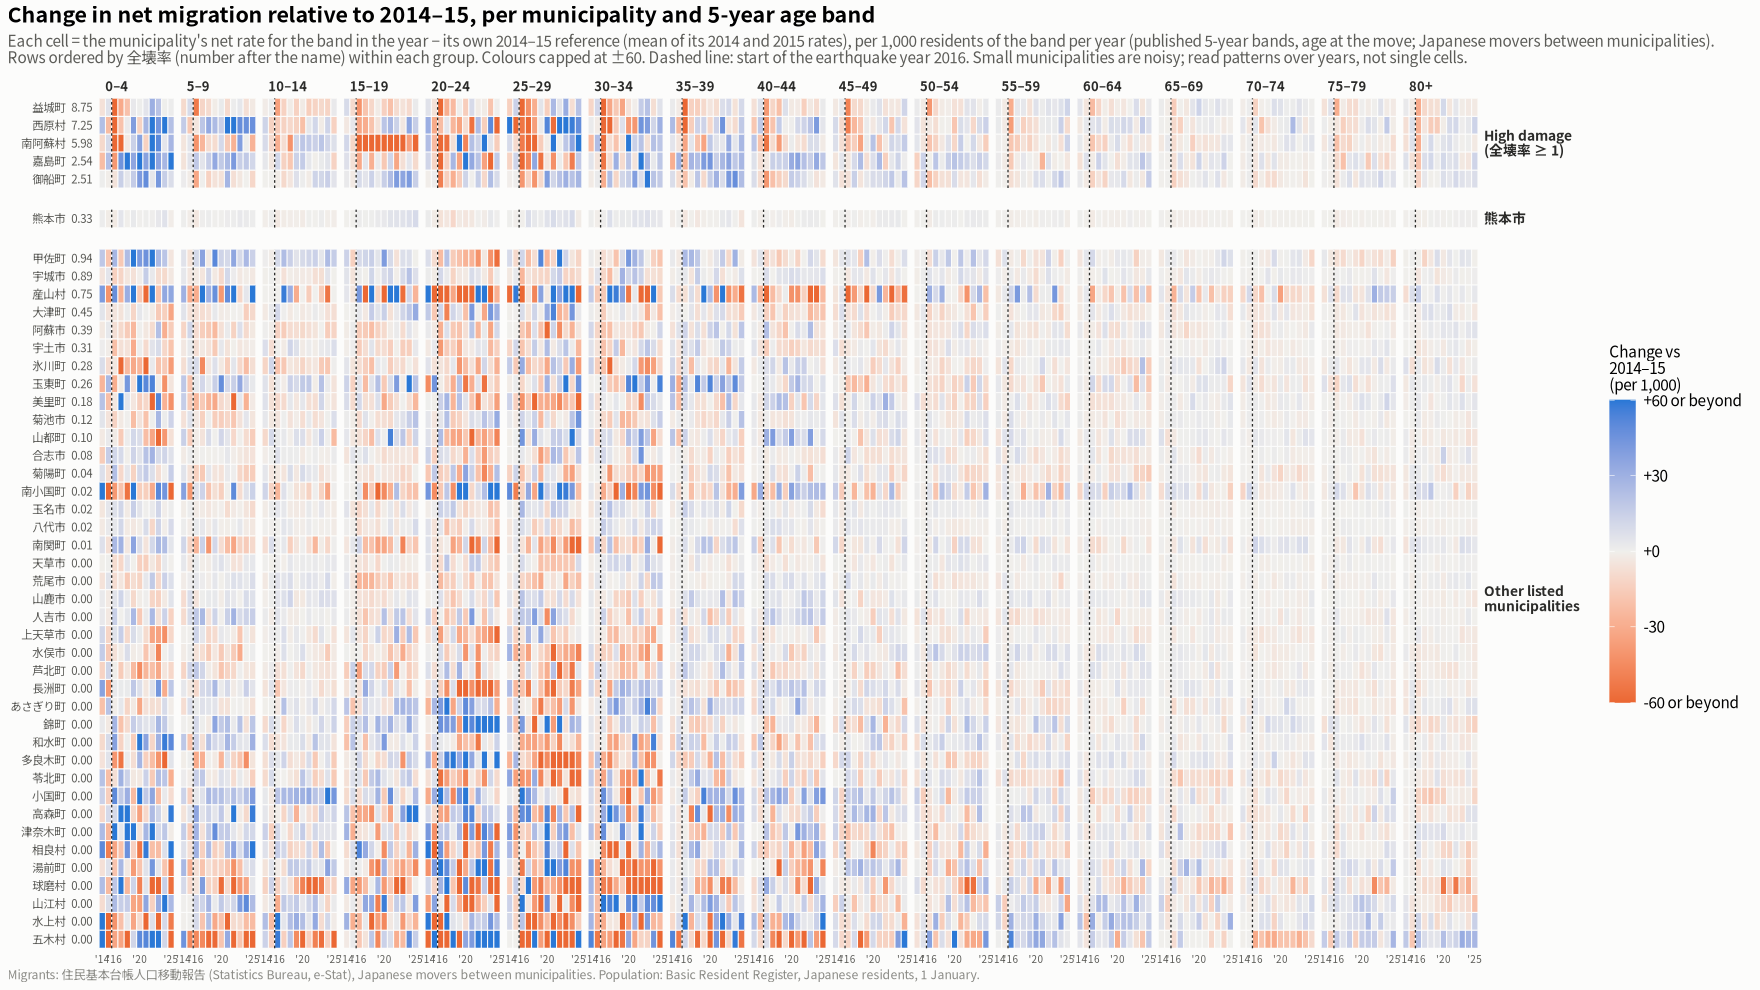

In [21]:
cap9 <- 60
p9 <- ggplot(mun5, aes(year, row, fill = pmax(pmin(change, cap9), -cap9))) +
  geom_tile(colour = surface, linewidth = 0.3) +
  geom_vline(xintercept = event_x - 0.5, colour = ink, linewidth = 0.4, linetype = "22") +
  facet_grid(group ~ band, scales = "free_y", space = "free_y",
             labeller = labeller(group = label_wrap_gen(14))) +
  change_fill(cap9, "Change vs\n2014–15\n(per 1,000)") +
  scale_fill_gradient2(low = "#eb6834", mid = "#f0efec", high = "#2a78d6", midpoint = 0, na.value = "#d9d8d3",
                       limits = c(-cap9, cap9), breaks = seq(-cap9, cap9, cap9 / 2),
                       labels = function(v) ifelse(abs(v) == cap9, sprintf("%+g or beyond", v), sprintf("%+g", v)),
                       name = "Change vs\n2014–15\n(per 1,000)") +
  scale_x_continuous(breaks = c(2014, 2016, 2020, 2025), labels = function(v) paste0("'", substr(v, 3, 4)), expand = c(0, 0)) +
  scale_y_discrete(expand = c(0, 0)) +
  labs(title = "Change in net migration relative to 2014–15, per municipality and 5-year age band",
       subtitle = paste0("Each cell = the municipality's net rate for the band in the year − its own 2014–15 reference (mean of its 2014 and 2015 rates), per 1,000 residents of the band per year ",
                         "(published 5-year bands, age at the move; Japanese movers between municipalities).\n",
                         "Rows ordered by 全壊率 (number after the name) within each group. Colours capped at ±", cap9, ". ",
                         "Dashed line: start of the earthquake year 2016. Small municipalities are noisy; read patterns over years, not single cells."),
       x = NULL, y = NULL, caption = src_note) +
  heat_theme() +
  theme(strip.text.y = element_text(angle = 0, hjust = 0, size = 9), strip.text.x = element_text(size = 8.5),
        axis.text.x = element_text(size = 6.5), panel.spacing.x = unit(0.15, "cm"))
show_save(p9, "09_band_change_by_muni", width = 30, height = 15)


### Figure 10: each band's own change, one panel per group

Each band's own net rate minus its 2014–15 reference (`chg5`; per 1,000 residents of the band, not of all ages as in figure 8), with one panel per group (high damage, 熊本市, other listed) and one line per 5-year age band. Colour shows the life stage (green 0–14, orange/red 15–39, blue 40–64, purple 65+); shade and line type tell the bands within a stage apart. All three panels share one y-axis, so the size of the changes can be compared directly between groups. The grey area marks the 2014–15 baseline years; the dashed line marks the earthquake year 2016.


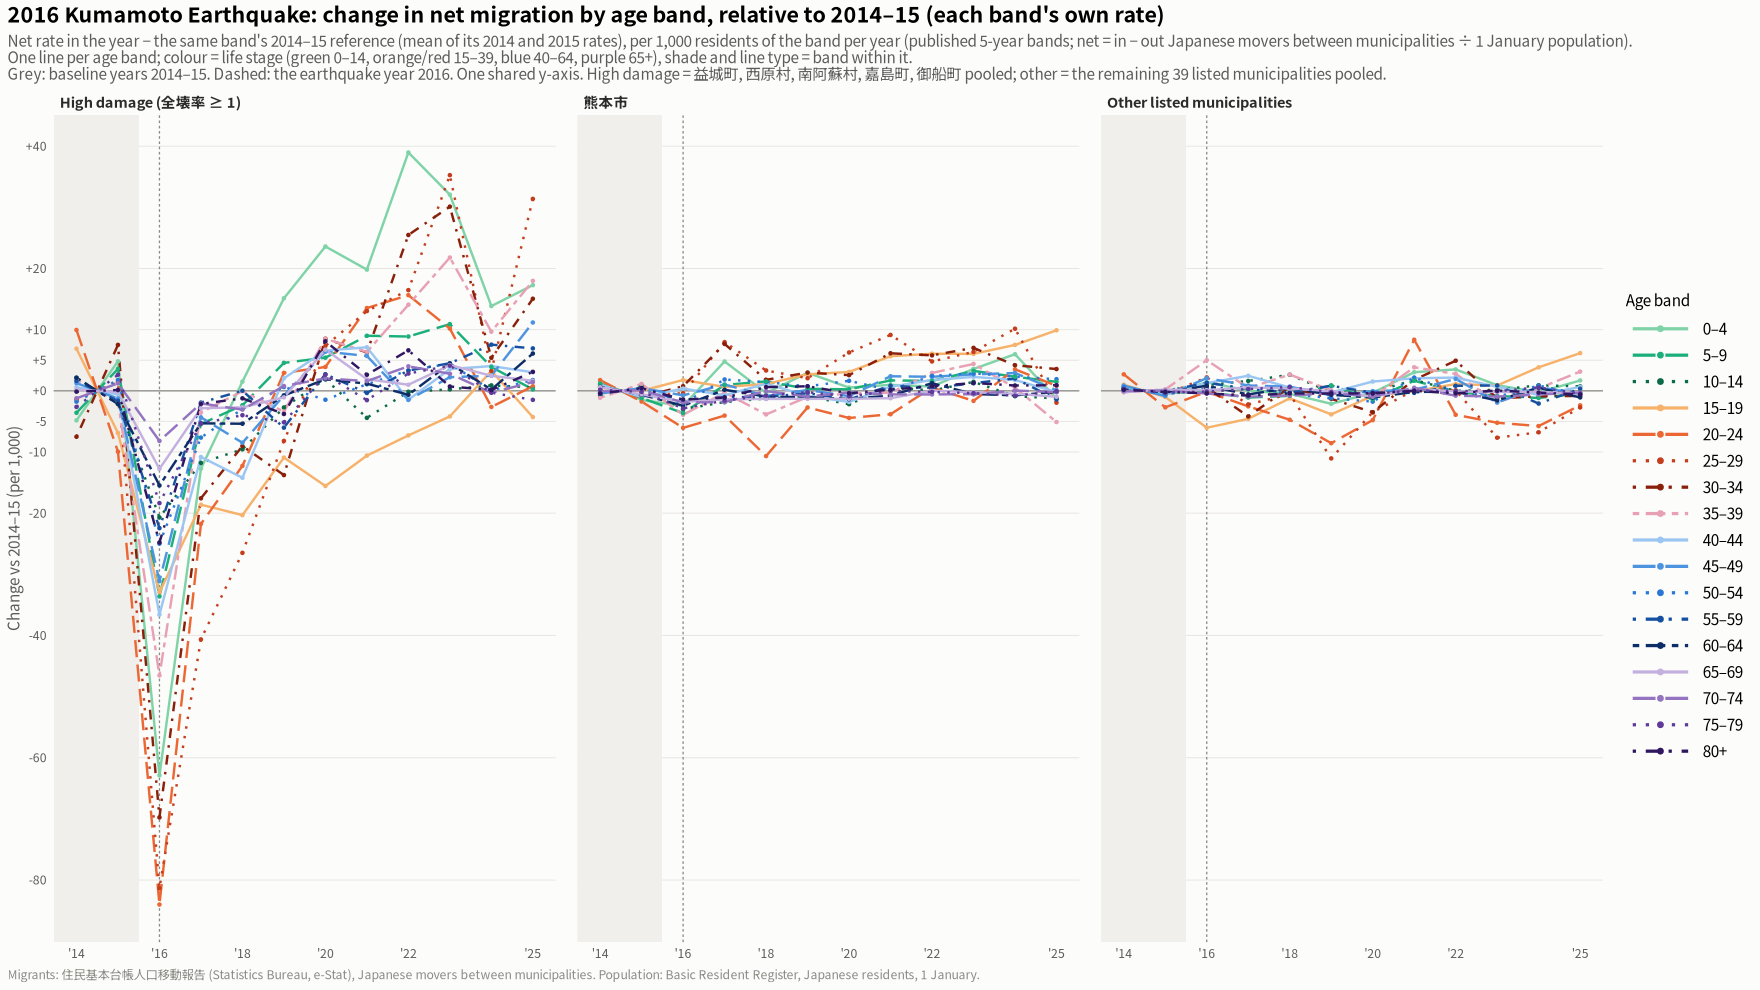

In [22]:
# band_family / band_cols are defined with figure 8
lty_seq <- c("solid", "longdash", "dotted", "dotdash", "twodash")
band_lty <- setNames(unlist(lapply(band_family, function(f) lty_seq[seq_along(f)]), use.names = FALSE), bands5)
p10 <- ggplot(chg5, aes(year, change, colour = band, linetype = band, group = band)) +
  annotate("rect", xmin = -Inf, xmax = base_year - 0.5, ymin = -Inf, ymax = Inf, fill = "#f0efec") +
  geom_hline(yintercept = 0, colour = ink3, linewidth = 0.4) +
  geom_vline(xintercept = event_x, colour = ink3, linewidth = 0.4, linetype = "22") +
  geom_line(linewidth = 0.75) +
  geom_point(size = 0.8) +
  facet_wrap(~group, nrow = 1) +
  scale_colour_manual(values = band_cols, labels = function(b) sub("_", "–", b), name = "Age band") +
  scale_linetype_manual(values = band_lty, labels = function(b) sub("_", "–", b), name = "Age band") +
  scale_x_continuous(breaks = c(2014, 2016, 2018, 2020, 2022, 2025), labels = function(v) paste0("'", substr(v, 3, 4))) +
  scale_y_continuous(breaks = sort(unique(c(seq(-100, 100, 20), -10, -5, 5, 10))), labels = function(v) sprintf("%+g", v)) +
  labs(title = "2016 Kumamoto Earthquake: change in net migration by age band, relative to 2014–15 (each band's own rate)",
       subtitle = paste0("Net rate in the year − the same band's 2014–15 reference (mean of its 2014 and 2015 rates), per 1,000 residents of the band per year (published 5-year bands; ",
                         "net = in − out Japanese movers between municipalities ÷ 1 January population).\n",
                         "One line per age band; colour = life stage (green 0–14, orange/red 15–39, blue 40–64, purple 65+), shade and line type = band within it.\nGrey: baseline years 2014–15. Dashed: the earthquake year 2016. ",
                         "One shared y-axis. High damage = 益城町, 西原村, 南阿蘇村, 嘉島町, 御船町 pooled; other = the remaining 39 listed municipalities pooled."),
       x = NULL, y = "Change vs 2014–15 (per 1,000)", caption = src_note) +
  base_theme() +
  theme(legend.position = "right", legend.justification = "center") +
  guides(colour = guide_legend(ncol = 1, override.aes = list(linewidth = 1, size = 1.5)),
         linetype = guide_legend(ncol = 1)) +
  theme(legend.key.width = unit(1.6, "cm"))
show_save(p10, "10_band_change_lines", width = 18, height = 7)


### Figure 11: heatmap of each band's change

The same values as figure 10 (`chg5`): each band's own net rate minus its 2014–15 reference, per 1,000 residents of the band. One panel per group, one row per band; the number in each cell is the change, rounded. Colours are capped at ±40.


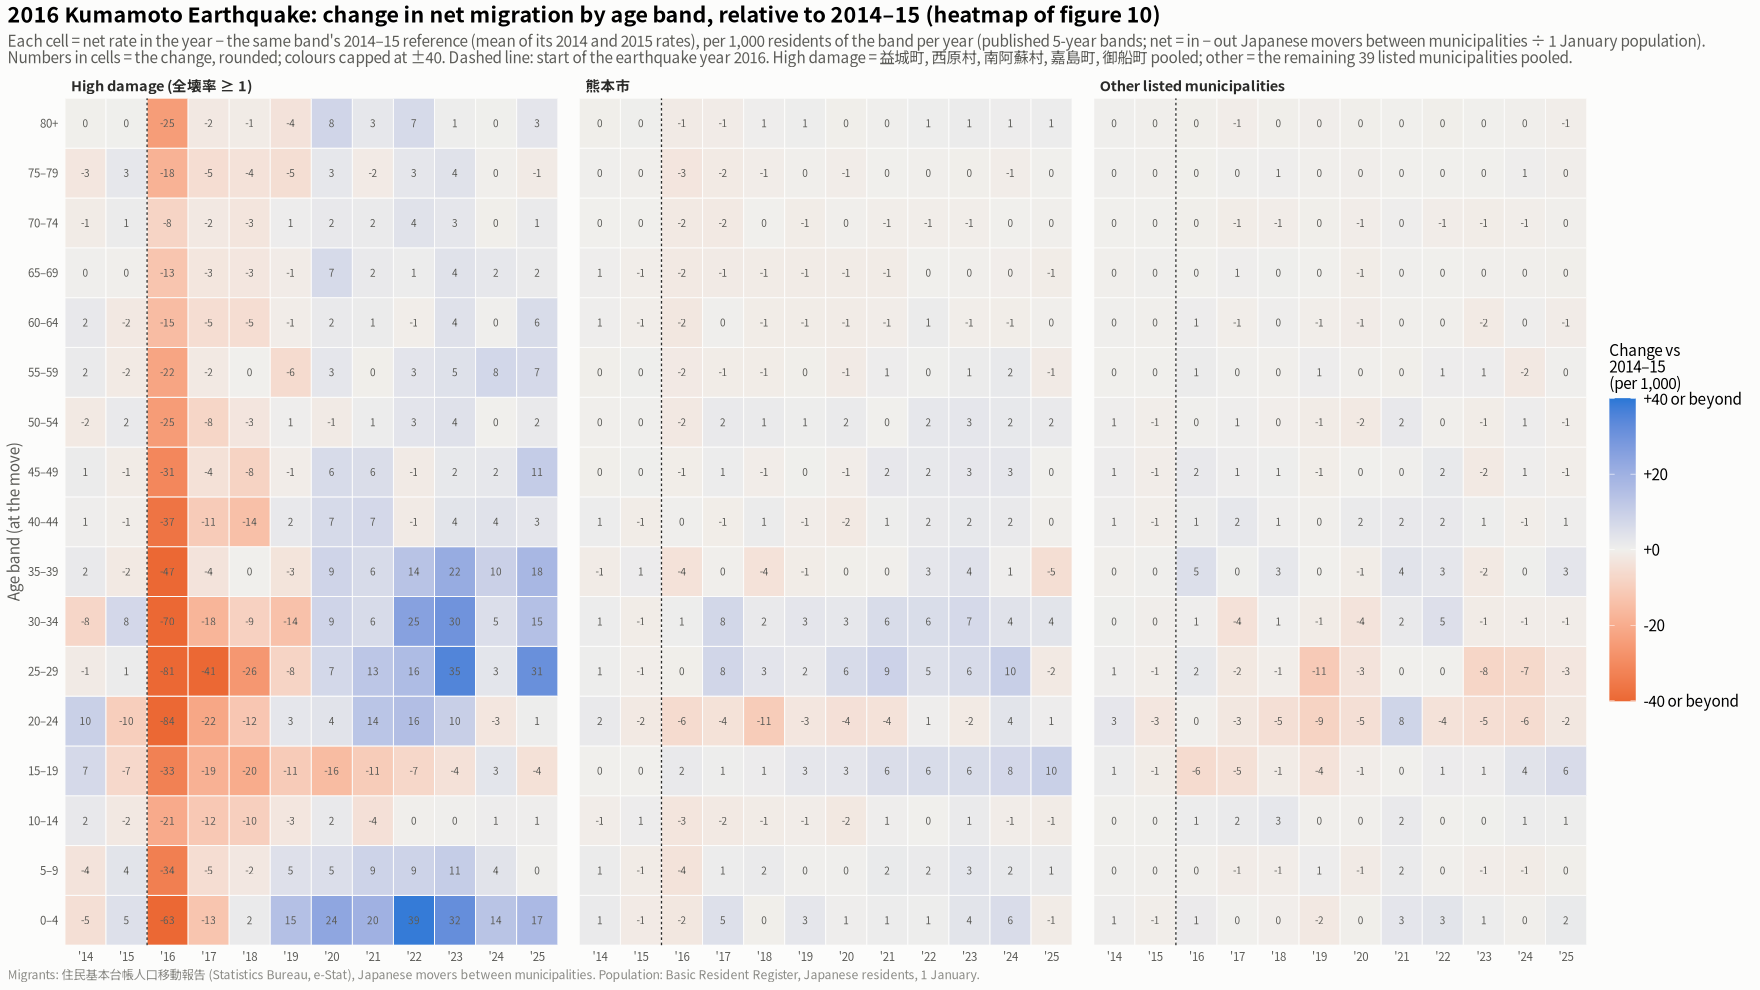

In [23]:
cap11 <- 40
p11 <- ggplot(chg5, aes(year, band, fill = pmax(pmin(change, cap11), -cap11))) +
  geom_tile(colour = surface, linewidth = 0.3) +
  geom_text(aes(label = ifelse(abs(change) < 0.5, "0", sprintf("%.0f", change))), size = 2.3, colour = ink2, family = jp_font) +
  geom_vline(xintercept = event_x - 0.5, colour = ink, linewidth = 0.4, linetype = "22") +
  facet_wrap(~group, nrow = 1) +
  change_fill(cap11, "Change vs\n2014–15\n(per 1,000)") +
  scale_x_continuous(breaks = years, labels = function(v) paste0("'", substr(v, 3, 4)), expand = c(0, 0)) +
  scale_y_discrete(labels = function(b) sub("_", "–", b), expand = c(0, 0)) +
  labs(title = "2016 Kumamoto Earthquake: change in net migration by age band, relative to 2014–15 (heatmap of figure 10)",
       subtitle = paste0("Each cell = net rate in the year − the same band's 2014–15 reference (mean of its 2014 and 2015 rates), per 1,000 residents of the band per year (published 5-year bands; ",
                         "net = in − out Japanese movers between municipalities ÷ 1 January population).\n",
                         "Numbers in cells = the change, rounded; colours capped at ±", cap11, ". Dashed line: start of the earthquake year 2016. ",
                         "High damage = 益城町, 西原村, 南阿蘇村, 嘉島町, 御船町 pooled; other = the remaining 39 listed municipalities pooled."),
       x = NULL, y = "Age band (at the move)", caption = src_note) +
  heat_theme()
show_save(p11, "11_band_change_heat", width = 18, height = 7.5)


### Figure 12: net migration rate by age band's contribution (levels, no baseline)

The same as figure 8, but showing the **level** of net migration rather than the change from 2014–15. Each segment is a band's net movers (in − out) ÷ the group's all-ages population on 1 January, per 1,000 per year (`contrib5$contrib`). The segments add up to the all-ages net migration rate (dashed line). Inflows stack above 0 and outflows below 0, with the youngest band next to the zero line. This shows the usual pre-quake pattern (for example, the departure of people aged 15–24 from small towns) next to the shock, and figure 8 removes it.

group,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
High damage (全壊率 ≥ 1),4.6,4.2,-29.7,-4.4,-1.9,2.4,8.9,7.7,10.4,12.1,6.8,9.6
熊本市,-0.1,-0.6,-2.1,0.3,-0.8,-0.2,-0.4,0.9,1.5,1.9,1.9,0.1
Other listed municipalities,-3.1,-3.8,-2.9,-3.8,-3.3,-4.5,-4.2,-2.1,-2.7,-4.1,-3.7,-3.3


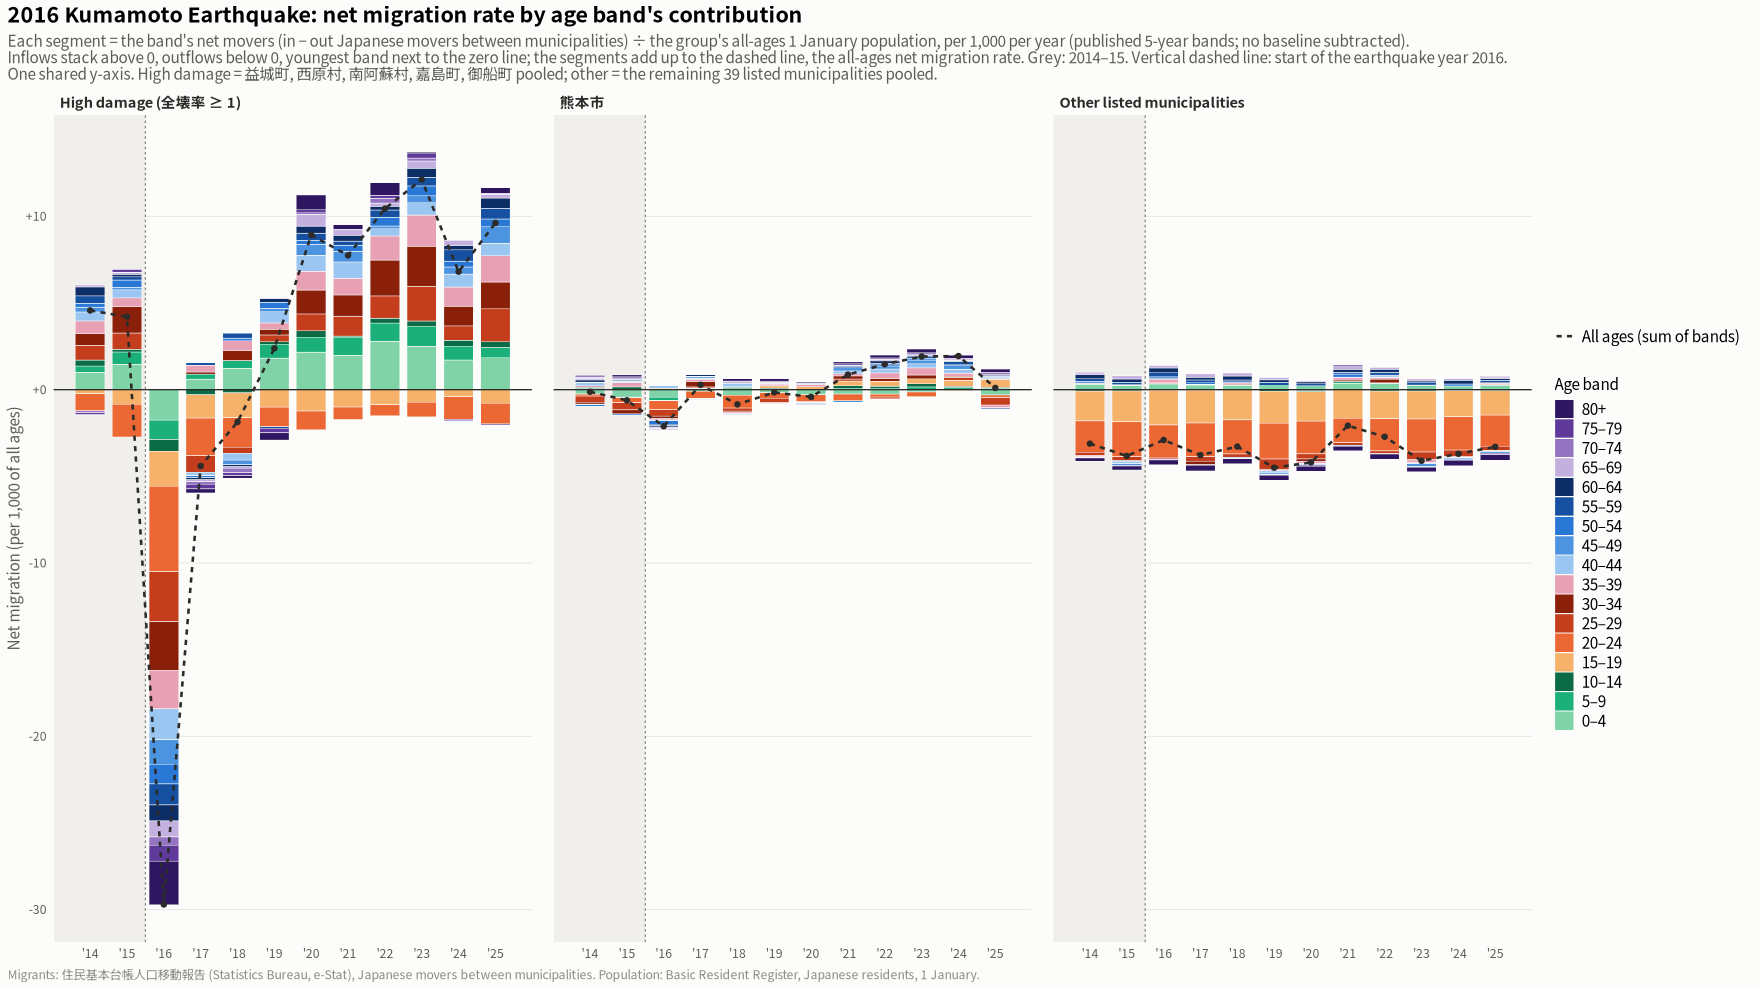

In [24]:
tot12 <- contrib5 |> group_by(group, year) |> summarise(rate = sum(contrib), .groups = "drop")

# Check: bands add up to the all-ages net rate
chk12 <- yr5 |> group_by(group, year) |> summarise(rate_all = 1000 * sum(net) / sum(pop), .groups = "drop") |>
  mutate(group = factor(group, levels = group_levels)) |>
  inner_join(tot12, by = c("group", "year"))
stopifnot(max(abs(chk12$rate_all - chk12$rate)) < 1e-9)

# Table: all-ages net migration rate (per 1,000), by group
tot12 |> mutate(rate = round(rate, 1)) |> pivot_wider(names_from = year, values_from = rate) |> as.data.frame()

p12 <- ggplot(contrib5, aes(year, contrib)) +
  annotate("rect", xmin = -Inf, xmax = base_year - 0.5, ymin = -Inf, ymax = Inf, fill = "#f0efec") +
  geom_col(aes(fill = band), width = 0.8, colour = surface, linewidth = 0.15,
           position = position_stack(reverse = TRUE)) +  # youngest band next to zero, oldest outermost
  geom_hline(yintercept = 0, colour = ink, linewidth = 0.4) +
  geom_vline(xintercept = event_x - 0.5, colour = ink3, linewidth = 0.4, linetype = "22") +
  geom_line(data = tot12, aes(y = rate, linetype = "All ages (sum of bands)"), colour = ink, linewidth = 0.8) +
  geom_point(data = tot12, aes(y = rate), colour = ink, size = 1.4) +
  facet_wrap(~group, nrow = 1) +
  scale_fill_manual(values = band_cols, labels = function(b) sub("_", "–", b), name = "Age band",
                    guide = guide_legend(ncol = 1, reverse = TRUE, order = 2)) +
  scale_linetype_manual(values = c("All ages (sum of bands)" = "22"), name = NULL,
                        guide = guide_legend(order = 1, override.aes = list(linewidth = 0.8))) +
  scale_x_continuous(breaks = years, labels = function(v) paste0("'", substr(v, 3, 4))) +
  scale_y_continuous(labels = function(v) sprintf("%+g", v)) +
  labs(title = "2016 Kumamoto Earthquake: net migration rate by age band's contribution",
       subtitle = paste0("Each segment = the band's net movers (in − out Japanese movers between municipalities) ÷ the group's all-ages 1 January population, per 1,000 per year ",
                         "(published 5-year bands; no baseline subtracted).\n",
                         "Inflows stack above 0, outflows below 0, youngest band next to the zero line; the segments add up to the dashed line, the all-ages net migration rate. ",
                         "Grey: 2014–15. Vertical dashed line: start of the earthquake year 2016.\n",
                         "One shared y-axis. High damage = 益城町, 西原村, 南阿蘇村, 嘉島町, 御船町 pooled; other = the remaining 39 listed municipalities pooled."),
       x = NULL, y = "Net migration (per 1,000 of all ages)", caption = src_note) +
  base_theme() +
  theme(legend.position = "right", legend.justification = "center", legend.key.size = unit(0.45, "cm"))
show_save(p12, "12_band_net_stacked", width = 18, height = 7.5)


### Figure 13: 全壊率 vs net migration in 2016, by municipality

One point per listed municipality (n = 45).

- **x:** 全壊率 (sheet `1_市町村一覧`), linear scale. 39 of the 45 municipalities are below 1, so they crowd near 0.
- **y, left panel:** the all-ages net migration rate in calendar 2016: 1000 · (in − out) ÷ the 2016-01-01 population. These are Japanese movers between municipalities, all ages.
- **y, right panel:** the same rate minus the municipality's own 2014–15 mean. This removes each town's usual pre-quake loss or gain.
- **Point size:** 2016 population. **Colour:** the 3r group.
- **ρ:** Spearman correlation with a two-sided permutation p (10,000 draws, seed 0), as in the protocol's dose–response analysis.
- **Dashed slope:** OLS fit per panel (unweighted), for reference.

measure,rho,p,slope,lab
<fct>,<dbl>,<dbl>,<dbl>,<chr>
"Net migration rate, 2016",-0.1320526,0.38806119,-3.982992,"Spearman ρ = -0.13, permutation p = 0.388; OLS slope -4.0 per 1 point of 全壊率"
2016 minus the municipality's 2014–15 mean,-0.5433500,0.00009999,-5.409009,"Spearman ρ = -0.54, permutation p < 0.001; OLS slope -5.4 per 1 point of 全壊率"


code,net_2016,base,pop_2016,change_2016,short,zenkai_rate,group
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<fct>
43443,-38.23,8.81,34503,-47.04,益城町,8.75,High damage (全壊率 ≥ 1)
43432,-25.44,3.20,7037,-28.64,西原村,7.25,High damage (全壊率 ≥ 1)
43433,-39.32,-2.63,11649,-36.69,南阿蘇村,5.98,High damage (全壊率 ≥ 1)
43442,-13.38,6.23,9196,-19.61,嘉島町,2.54,High damage (全壊率 ≥ 1)
43441,-16.93,0.14,17665,-17.06,御船町,2.51,High damage (全壊率 ≥ 1)
43444,-4.06,-6.67,11082,2.61,甲佐町,0.94,Other listed municipalities
43213,-4.65,-3.23,60634,-1.42,宇城市,0.89,Other listed municipalities
43425,-16.60,-4.07,1566,-12.53,産山村,0.75,Other listed municipalities
43403,1.98,4.92,33904,-2.95,大津町,0.45,Other listed municipalities


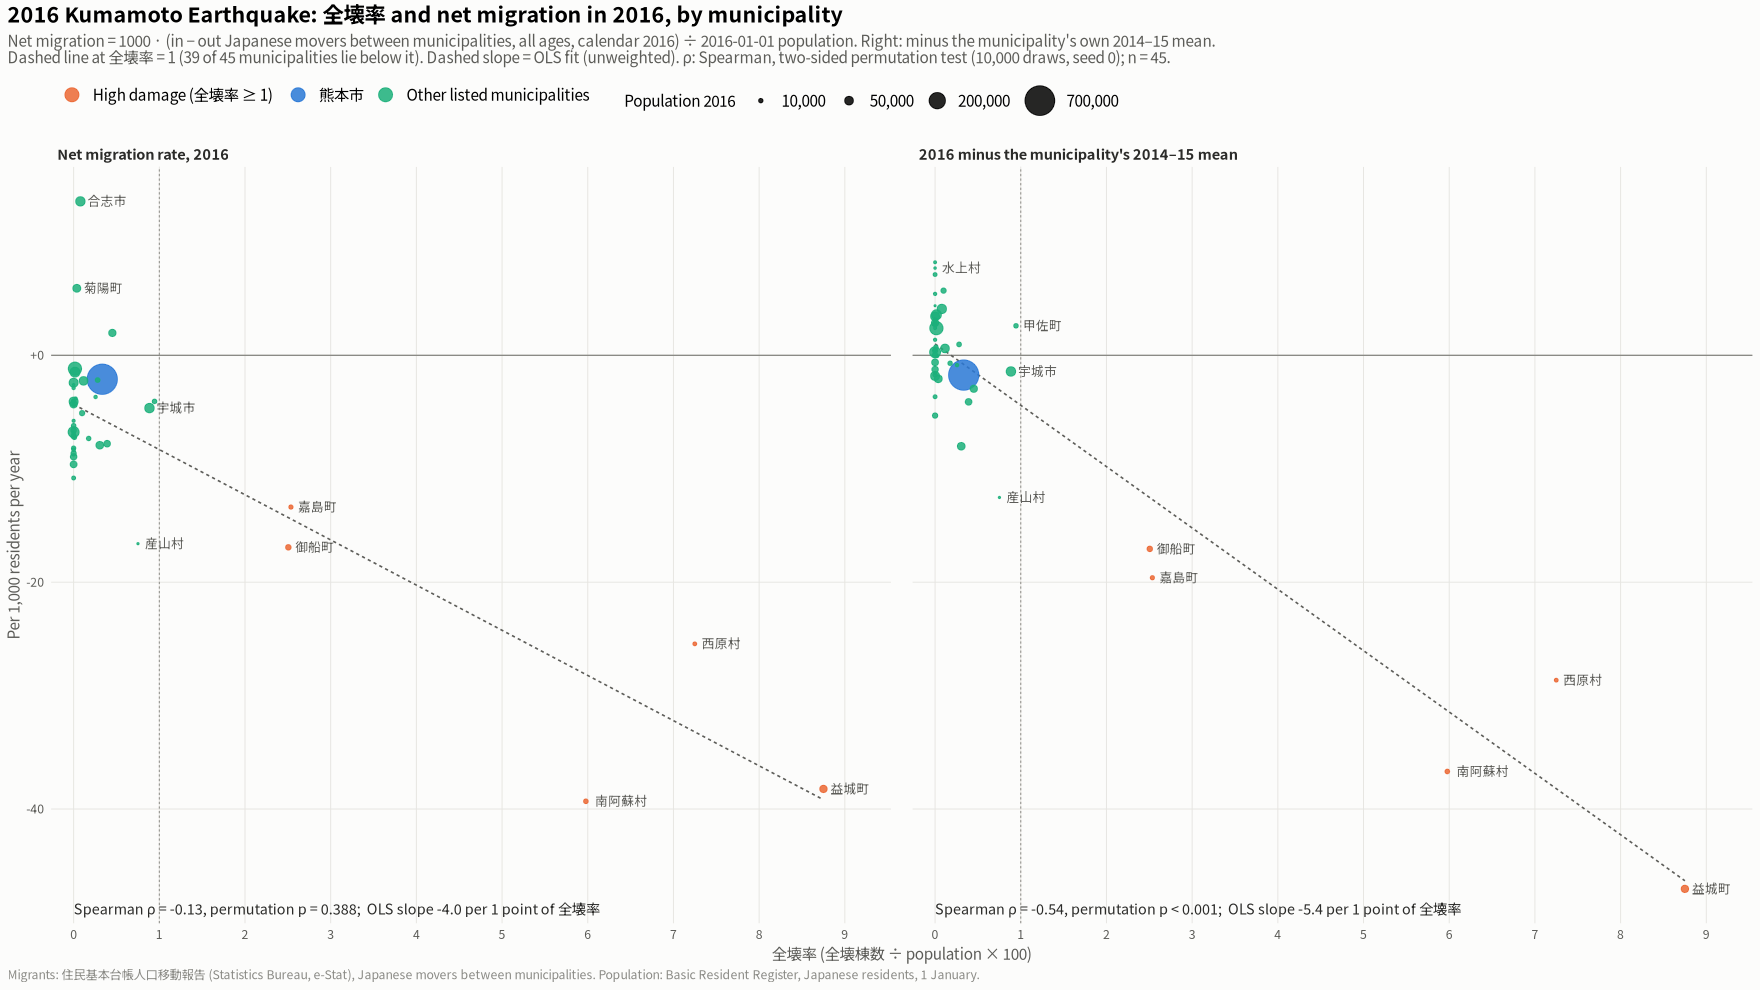

In [25]:
tot13 <- mig5 |> filter(age_band == "total") |>
  pivot_wider(names_from = direction, values_from = n) |>
  inner_join(pop5 |> filter(age_band == "total") |> select(code, year, pop = n), by = c("code", "year")) |>
  mutate(rate = 1000 * (`in` - out) / pop)
sc13 <- tot13 |>
  group_by(code) |>
  summarise(net_2016 = rate[year == 2016], base = mean(rate[year %in% 2014:2015]),
            pop_2016 = pop[year == 2016], .groups = "drop") |>
  mutate(change_2016 = net_2016 - base) |>
  inner_join(study |> select(code, short, zenkai_rate, group), by = "code") |>
  mutate(group = factor(group, levels = group_levels))
stopifnot(nrow(sc13) == nrow(study), !anyNA(sc13$net_2016))

perm_rho <- function(x, y, B = 10000, seed = 0) {
  rho <- cor(x, y, method = "spearman")
  set.seed(seed)
  null <- replicate(B, cor(x, sample(y), method = "spearman"))
  c(rho = rho, p = (1 + sum(abs(null) >= abs(rho))) / (B + 1))
}
measures13 <- c(net_2016 = "Net migration rate, 2016", change_2016 = "2016 minus the municipality's 2014–15 mean")
long13 <- sc13 |>
  pivot_longer(c(net_2016, change_2016), names_to = "measure", values_to = "y") |>
  mutate(measure = factor(measures13[measure], levels = measures13))
stats13 <- long13 |> group_by(measure) |>
  summarise(rho = perm_rho(zenkai_rate, y)["rho"], p = perm_rho(zenkai_rate, y)["p"], .groups = "drop") |>
  left_join(long13 |> group_by(measure) |>
              summarise(slope = coef(lm(y ~ zenkai_rate))[2], .groups = "drop"), by = "measure") |>
  mutate(lab = sprintf("Spearman ρ = %.2f, permutation p %s;  OLS slope %.1f per 1 point of 全壊率",
                       rho, ifelse(p < 0.001, "< 0.001", sprintf("= %.3f", p)), slope))
stats13 |> as.data.frame()
sc13 |> arrange(desc(zenkai_rate)) |> head(10) |>
  mutate(across(c(zenkai_rate, net_2016, base, change_2016), \(v) round(v, 2))) |> as.data.frame()

lab13 <- long13 |> group_by(measure) |>
  filter(zenkai_rate >= 0.7 | rank(y) <= 3 | rank(-y) <= 2) |> ungroup()
p13 <- ggplot(long13, aes(zenkai_rate, y)) +
  geom_hline(yintercept = 0, colour = ink3, linewidth = 0.4) +
  geom_vline(xintercept = 1, colour = ink3, linewidth = 0.3, linetype = "22") +
  geom_smooth(method = "lm", formula = y ~ x, se = FALSE, colour = ink2, linewidth = 0.5, linetype = "22") +
  geom_point(aes(colour = group, size = pop_2016), alpha = 0.85) +
  geom_text(data = lab13, aes(label = short), size = 2.9, colour = ink2, family = jp_font,
            hjust = -0.18, vjust = 0.5, check_overlap = TRUE) +
  geom_text(data = stats13, aes(x = 0, y = -Inf, label = lab), inherit.aes = FALSE,
            hjust = 0, vjust = -0.8, size = 3.3, colour = ink, family = jp_font) +
  facet_wrap(~measure, nrow = 1) +
  scale_x_continuous(breaks = 0:10, expand = expansion(mult = c(0.03, 0.09))) +
  scale_y_continuous(labels = function(v) sprintf("%+g", v)) +
  scale_colour_manual(values = group_cols, name = NULL) +
  scale_size_area(max_size = 9, breaks = c(1e4, 5e4, 2e5, 7e5), labels = scales::comma, name = "Population 2016") +
  labs(title = "2016 Kumamoto Earthquake: 全壊率 and net migration in 2016, by municipality",
       subtitle = paste0("Net migration = 1000 · (in − out Japanese movers between municipalities, all ages, calendar 2016) ÷ 2016-01-01 population. ",
                         "Right: minus the municipality's own 2014–15 mean.\n",
                         "Dashed line at 全壊率 = 1 (39 of 45 municipalities lie below it). ",
                         "Dashed slope = OLS fit (unweighted). ρ: Spearman, two-sided permutation test (10,000 draws, seed 0); n = ", nrow(sc13), "."),
       x = "全壊率 (全壊棟数 ÷ population × 100)", y = "Per 1,000 residents per year", caption = src_note) +
  base_theme() +
  theme(panel.grid.major.x = element_line(colour = grid_col, linewidth = 0.3)) +
  guides(colour = guide_legend(order = 1, override.aes = list(size = 4)), size = guide_legend(order = 2))
show_save(p13, "13_zenkai_vs_net_2016", width = 16, height = 7.5)


### Figure 14: 全壊率 vs the change in net migration in 2016, relative to 2014–15

The right panel of figure 13 on its own. y is the municipality's all-ages net migration rate in 2016 minus its own 2014–15 mean, per 1,000 residents per year. x is 全壊率 on a linear scale. Point size is the 2016 population and colour is the 3r group. The dashed line is the OLS fit, weighted equally across municipalities and shown for reference only. ρ is Spearman with a permutation p, as in figure 13.

OLS slope: -5.41 per 1,000 per 1 point of 全壊率 (SE 0.33); Spearman rho = -0.54, permutation p = 0.0001


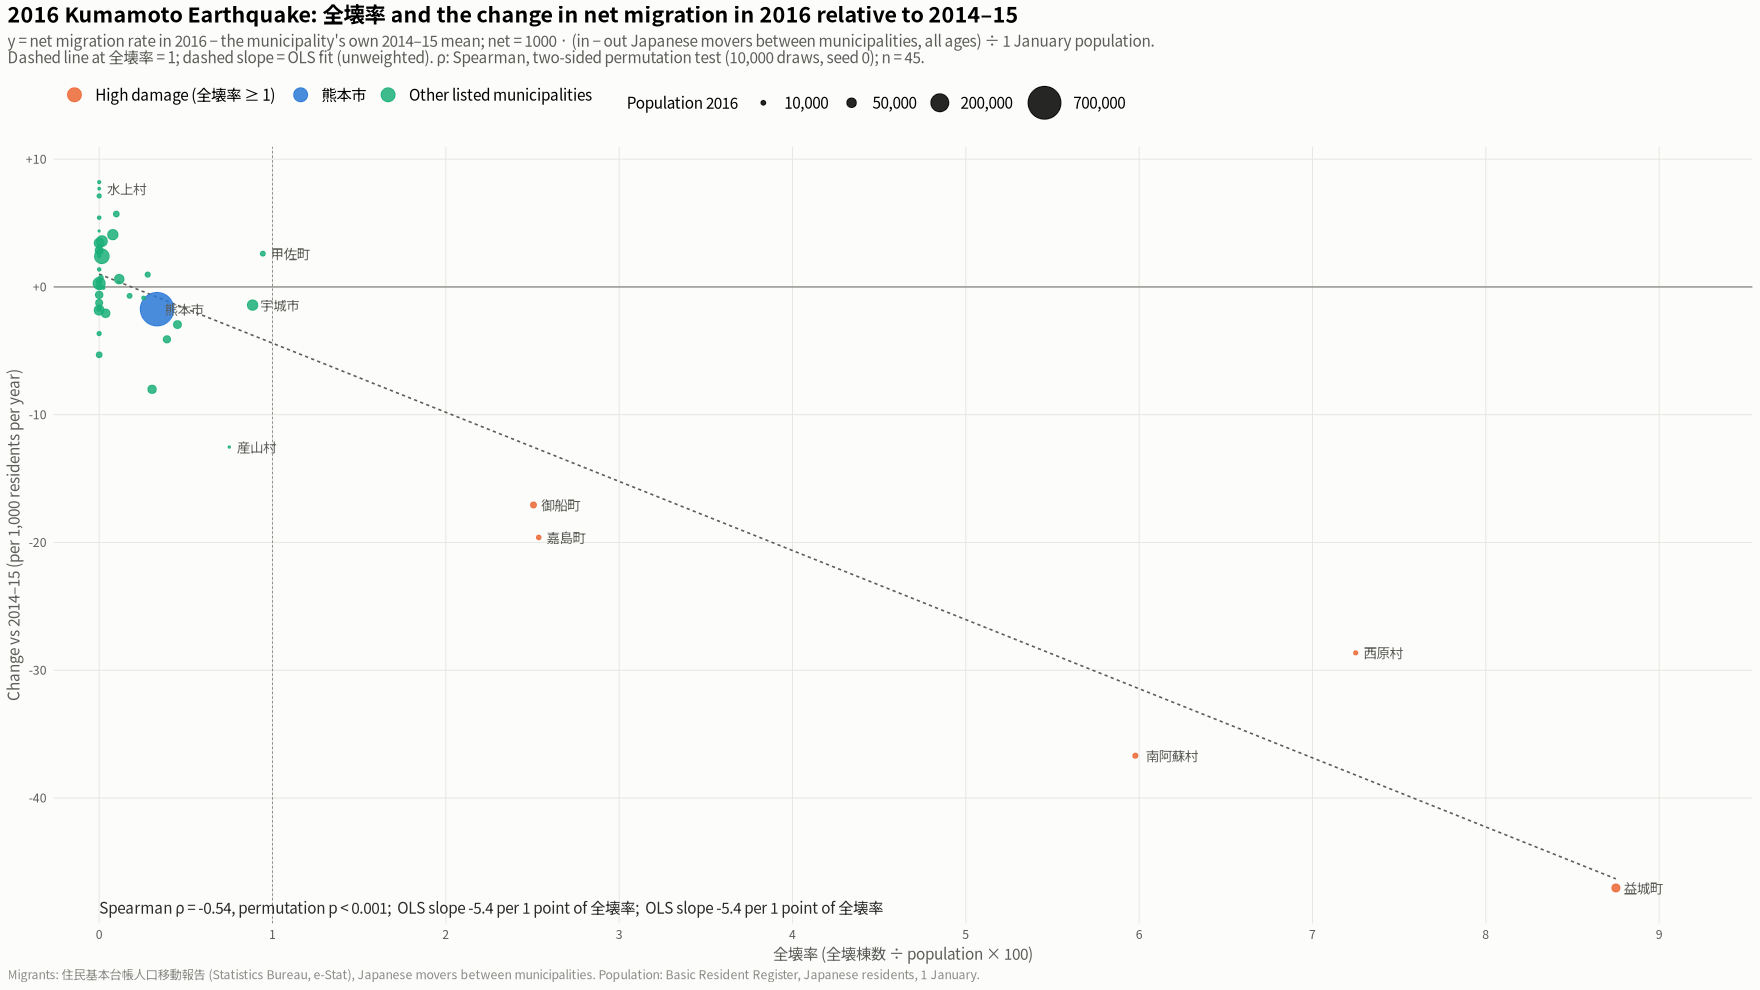

In [26]:
rel14 <- long13 |> filter(measure == measures13[["change_2016"]])
st14 <- stats13 |> filter(measure == measures13[["change_2016"]])
fit14 <- lm(y ~ zenkai_rate, data = rel14)
cat(sprintf("OLS slope: %.2f per 1,000 per 1 point of 全壊率 (SE %.2f); Spearman rho = %.2f, permutation p = %.4f\n",
            coef(fit14)[2], summary(fit14)$coef[2, 2], st14$rho, st14$p))
lab14 <- rel14 |> filter(zenkai_rate >= 0.7 | code == "43100" | rank(y) <= 3 | rank(-y) <= 2)

p14 <- ggplot(rel14, aes(zenkai_rate, y)) +
  geom_hline(yintercept = 0, colour = ink3, linewidth = 0.4) +
  geom_vline(xintercept = 1, colour = ink3, linewidth = 0.3, linetype = "22") +
  geom_smooth(method = "lm", formula = y ~ x, se = FALSE, colour = ink2, linewidth = 0.5, linetype = "22") +
  geom_point(aes(colour = group, size = pop_2016), alpha = 0.85) +
  geom_text(data = lab14, aes(label = short), size = 3.1, colour = ink2, family = jp_font,
            hjust = -0.2, vjust = 0.5, check_overlap = TRUE) +
  annotate("text", x = 0, y = -Inf, hjust = 0, vjust = -0.8, size = 3.5, colour = ink, family = jp_font,
           label = sprintf("%s;  OLS slope %.1f per 1 point of 全壊率", st14$lab, coef(fit14)[2])) +
  scale_x_continuous(breaks = 0:10, expand = expansion(mult = c(0.03, 0.09))) +
  scale_y_continuous(labels = function(v) sprintf("%+g", v)) +
  scale_colour_manual(values = group_cols, name = NULL) +
  scale_size_area(max_size = 10, breaks = c(1e4, 5e4, 2e5, 7e5), labels = scales::comma, name = "Population 2016") +
  labs(title = "2016 Kumamoto Earthquake: 全壊率 and the change in net migration in 2016 relative to 2014–15",
       subtitle = paste0("y = net migration rate in 2016 − the municipality's own 2014–15 mean; net = 1000 · (in − out Japanese movers between municipalities, all ages) ÷ 1 January population.\n",
                         "Dashed line at 全壊率 = 1; dashed slope = OLS fit (unweighted). ρ: Spearman, two-sided permutation test (10,000 draws, seed 0); n = ", nrow(rel14), "."),
       x = "全壊率 (全壊棟数 ÷ population × 100)", y = "Change vs 2014–15 (per 1,000 residents per year)", caption = src_note) +
  base_theme() +
  theme(panel.grid.major.x = element_line(colour = grid_col, linewidth = 0.3)) +
  guides(colour = guide_legend(order = 1, override.aes = list(size = 4)), size = guide_legend(order = 2))
show_save(p14, "14_zenkai_vs_net_change_2016", width = 11, height = 7.5)
